# f4_7: 메모리를 줄인 연도별 ACR 계산

diff_step=1e-5의 전체 격자에 동일한 ESS를 적용하되, 격자를 4,096점씩 검사합니다. 연도별 평균·규모 차이에 필요한 보간 끝점만 Mu와 부트스트랩을 계산하므로 전체 격자×기업×반복 배열을 만들지 않습니다. diff_step으로 한 번 나누는 ACR, XGB 탐색150·반복50·부트스트랩5000, 표본·가중치·seed·규모 차이 정의를 유지합니다. CPU 동시 학습 수만 예시에서 2로 제한합니다.

원본 f4_7은 수정하지 않았습니다. 데이터 경로도 현재 원본의 gpt_continuous.xlsx를 그대로 사용합니다. memory_mode=event_only는 기존 연도별 평균 그래프용입니다. 전체 처치수준 곡선과 동시 신뢰띠·누적 곡선이 필요한 경우 memory_mode=full을 사용하세요. 해당 모드는 기존 전체 배열을 저장합니다.

격자 간격을 바꾸거나 ESS 지지점·공백 처리 규칙을 바꾸지 않습니다. bridge와 strict 모두 선택한 규칙으로 필요한 끝점을 구합니다.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import norm
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from threadpoolctl import threadpool_limits
from joblib import Parallel, delayed, parallel_config
from time import perf_counter
import os
import json
import warnings

# 'industry': 산업 단위 / 'firm': 기업 단위. 함수 인자로도 개별 지정 가능.
BOOTSTRAP_UNIT = 'industry'

# 학습량·통계 규칙은 첫 번째 파일과 같고, 아래 옵션은 GPS와 계산 자원만 제어한다.
FAST_OPTIONS = {'gps_model': 'spline', 'gps_n_knots': 3, 'gps_degree': 3,
                'search_n_jobs': min(4, os.cpu_count() or 1), 'crossfit_n_jobs': min(4, os.cpu_count() or 1), 'xgb_n_jobs': 1,
                'max_prediction_rows': 50000, 'bootstrap_batch_points': 128,
                'support_batch_points': 256, 'grid_chunk_points': 4096, 'memory_mode': 'event_only', 'deduplicate_tree_predictions': True, 'verbose': True}

def get_fast_options(options=None):
    unknown = set(options or {}) - FAST_OPTIONS.keys()
    if unknown:
        raise ValueError(f'지원하지 않는 옵션: {sorted(unknown)}. 결과모형은 원본의 exact·150회 탐색을 유지합니다.')
    config = {**FAST_OPTIONS, **(options or {})}
    if config['memory_mode'] not in ('event_only', 'full'):
        raise ValueError('memory_mode must be event_only or full')
    if config['gps_model'] not in ('spline', 'linear'):
        raise ValueError("gps_model은 'spline' 또는 'linear'입니다.")
    for key in ('gps_n_knots', 'gps_degree', 'max_prediction_rows', 'bootstrap_batch_points', 'support_batch_points', 'grid_chunk_points'):
        minimum = 2 if key == 'gps_n_knots' else 1
        if not isinstance(config[key], (int, np.integer)) or config[key] < minimum:
            raise ValueError(f'{key}는 {minimum} 이상의 정수여야 합니다.')
    for key in ('search_n_jobs', 'crossfit_n_jobs', 'xgb_n_jobs'):
        if not isinstance(config[key], (int, np.integer)) or config[key] == 0 or config[key] < -1:
            raise ValueError(f'{key}는 -1 또는 양의 정수여야 합니다.')
    if not isinstance(config['deduplicate_tree_predictions'], (bool, np.bool_)):
        raise ValueError('deduplicate_tree_predictions must be boolean')
    return config

def make_gps_model(continuous, dummies, config, alpha=1.0):
    if config['gps_model'] == 'linear':
        return Pipeline([('scaler', StandardScaler()), ('Ridge', Ridge(alpha=alpha, solver='svd'))])
    spline = SplineTransformer(n_knots=config['gps_n_knots'], degree=config['gps_degree'],
                              knots='quantile', include_bias=False, extrapolation='linear')
    features = ColumnTransformer([('continuous', spline, continuous), ('dummies', 'passthrough', dummies)])
    return Pipeline([('features', features), ('scaler', StandardScaler()), ('Ridge', Ridge(alpha=alpha, solver='svd'))])

def _prepare_gps_fold(X, train, test, continuous, dummies, config):
    # 같은 fold의 스플라인·표준화·SVD를 평균모형, 분산모형, 모든 alpha에서 공유한다.
    transform = make_gps_model(continuous, dummies, config)[:-1]
    X_train = transform.fit_transform(X.iloc[train])
    X_test = transform.transform(X.iloc[test])
    offset = X_train.mean(axis=0)
    U, singular, Vt = np.linalg.svd(X_train - offset, full_matrices=False)
    return train, test, U, singular, (X_test - offset) @ Vt.T

def _gps_ridge_predict(fold, y, alphas, predict_train=False):
    train, _, U, singular, test_projection = fold
    target = y[train]
    mean = target.mean()
    projection = U.T @ (target - mean)
    alphas = np.atleast_1d(alphas).astype(float)
    coefficients = singular[:, None] * projection[:, None] / (singular[:, None] ** 2 + alphas[None, :])
    predicted = test_projection @ coefficients + mean
    if predict_train:
        fitted = U @ (singular[:, None] * coefficients) + mean
        return predicted, fitted
    return predicted

def _gps_best_alpha(folds, y, alphas):
    losses = [np.mean((_gps_ridge_predict(fold, y, alphas) - y[fold[1], None]) ** 2, axis=0) for fold in folds]
    return alphas[np.argmin(np.mean(losses, axis=0))]

# 전처리 함수
def merge_adjacent_divisions(df, major, prefix, ind_col='ind_code', year_col='Year', min_nunique=6, min_obs=6):
    mask = df['대분류'] == major
    df.loc[mask, 'ind_refined'] = prefix + '_' + df.loc[mask, '중분류']
    all_years = np.sort(df[year_col].dropna().unique())
    cats = sorted(df.loc[mask, 'ind_refined'].dropna().unique(), key=lambda x: int(x.split('_')[1]))
    current = []
    final = []
    for cat in cats:
        current.append(cat)
        sub = df[df['ind_refined'].isin(current)]
        n_ind = sub.groupby(year_col)[ind_col].nunique().reindex(all_years, fill_value=0)
        n_obs = sub.groupby(year_col).size().reindex(all_years, fill_value=0)
        if n_ind.min() >= min_nunique and n_obs.min() >= min_obs:
            final.append(current.copy())
            current = []
    if current:
        if final:
            final[-1].extend(current)
        else:
            final.append(current)
    mapping = {}
    for group in final:
        divs = [x.split('_')[1] for x in group]
        name = f'{prefix}_{divs[0]}' if len(group) == 1 else f'{prefix}_{divs[0]}_{divs[-1]}'
        for cat in group:
            mapping[cat] = name
    df['ind_refined'] = df['ind_refined'].replace(mapping)
    return df

def refine_industry_codes(df, ind_col='ind_code', year_col='Year', min_nunique=6, min_obs=6):
    """산업구조로 ind_refined와 산업 더미를 생성한다."""
    df = df.copy()
    division_to_major = {}
    major_ranges = {
        'A': range(1, 4), 'B': range(5, 9), 'C': range(10, 35), 'D': range(35, 36),
        'E': range(36, 40), 'F': range(41, 43), 'G': range(45, 48), 'H': range(49, 53),
        'I': range(55, 57), 'J': range(58, 64), 'K': range(64, 67), 'L': range(68, 69),
        'M': range(70, 74), 'N': range(74, 77), 'O': range(84, 85), 'P': range(85, 86),
        'Q': range(86, 88), 'R': range(90, 92), 'S': range(94, 97), 'T': range(97, 99), 'U': range(99, 100)
    }
    for major, divisions in major_ranges.items():
        for d in divisions:
            division_to_major[str(d).zfill(2)] = major
    df['중분류'] = df[ind_col].astype(str).str.zfill(3).str[:2]
    df['대분류'] = df['중분류'].map(division_to_major)
    non_mfg_macro = {
        'A': 'Primary_Infra', 'B': 'Primary_Infra', 'D': 'Primary_Infra', 'E': 'Primary_Infra',
        'F': 'Primary_Infra', 'G': 'Trade', 'H': 'Transport_Hospitality', 'I': 'Transport_Hospitality',
        'K': 'Finance', 'L': 'Finance', 'M': 'Professional_Business', 'N': 'Professional_Business',
        'P': 'Social_Service', 'Q': 'Social_Service', 'R': 'Personal_Service', 'S': 'Personal_Service'
    } # 
    df['ind_refined'] = df['대분류'].map(non_mfg_macro)
    all_years = np.sort(df[year_col].dropna().unique())
    df = merge_adjacent_divisions(df, 'C', 'MFG', ind_col, year_col, min_nunique, min_obs)
    df = merge_adjacent_divisions(df, 'J', 'ICT', ind_col, year_col, min_nunique, min_obs)
    categories = df['ind_refined'].dropna().unique()
    rare_groups = []
    for cat in categories:
        subset = df[df['ind_refined'] == cat]
        yearly_nunique = subset.groupby(year_col)[ind_col].nunique().reindex(all_years, fill_value=0)
        if yearly_nunique.min() < min_nunique:
            rare_groups.append(cat)
    if rare_groups:
        df['ind_refined'] = df['ind_refined'].replace(rare_groups, 'Other')
    industry_dummies = pd.get_dummies(df['ind_refined'], prefix='ind_dummy', drop_first=True, dtype=int)
    df = pd.concat([df, industry_dummies], axis=1)
    return df

def create_large_firm_dummy(df, base_year=2022):
    """기준연도 이전 매출로 규모를 구분한다. 산업 내 기업이 2개 이하면 미분류(-1)로 둔다."""
    df = df.copy()
    firm_sale = df[df['Year'] <= base_year].groupby(['ind_code', 'firm_code'])['sale'].mean().reset_index() # 회사별 평균값
    firm_sale['n_firms'] = firm_sale.groupby('ind_code')['firm_code'].transform('nunique') # 산업별 회사 수
    firm_sale['ind_median_size'] = firm_sale.groupby('ind_code')['sale'].transform('median') # 산업별 median
    firm_sale['large_firm'] = np.where(firm_sale['n_firms'] <= 1, -1, (firm_sale['sale'] >= firm_sale['ind_median_size']).astype(int))
    firm_sale['large_dummy'] = (firm_sale['large_firm'] == 1).astype(int)
    firm_sale['small_dummy'] = (firm_sale['large_firm'] == 0).astype(int)
    firm_map = firm_sale.set_index('firm_code')[['large_firm', 'large_dummy', 'small_dummy']]
    df = df.join(firm_map, on='firm_code')
    return df.dropna(subset=['large_firm']).copy()

def prepare_year_data(df, year, base_year=2022):
    """Join baseline by stable firm identifier; preserve original pre-period sign convention."""
    temp = df[df['Year'].isin([year, base_year])].copy()
    if temp.duplicated(['firm_code', 'Year']).any():
        raise ValueError('Duplicate firm_code-Year observations are not allowed.')
    base_values = temp[temp['Year'] == base_year].set_index('firm_code')['ln_firm_prod']
    temp['Y_base'] = temp['firm_code'].map(base_values)
    temp['Y_diff'] = temp['ln_firm_prod'] - temp['Y_base'] if year > base_year else temp['Y_base'] - temp['ln_firm_prod']
    return temp[temp['Year'] == year].dropna(subset=['Y_diff']).copy()


# d_grid 계산
def get_cluster_bandwidth(df, var_name='office_ratio', group_col='ind_code', min_bandwidth=0.01):
    """처치단위인 산업별 D 하나만 사용하여 bandwidth 계산."""
    D_group = df.groupby(group_col)[var_name].first().dropna().to_numpy()
    std = np.std(D_group)
    iqr = np.percentile(D_group, 75) - np.percentile(D_group, 25)
    sigma = min(std, iqr / 1.34) if iqr > 0 else std
    bandwidth = 2.34 * sigma * len(D_group) ** (-0.25) * 0.5
    return max(bandwidth, min_bandwidth)

def kernel_ess(D, d, bandwidth):
    """주어진 d에서 산업단위 kernel ESS 계산."""
    u = (D - d) / bandwidth
    weights = np.where(np.abs(u) <= 1, 0.75 * (1 - u ** 2) / bandwidth, 0)
    if np.sum(weights ** 2) == 0:
        return 0
    return weights.sum() ** 2 / np.sum(weights ** 2)

def filter_common_support(df_firm, years, var_name, base_year=2022, group_col="ind_code",
                          min_ess_prime=10, max_d=10, min_bandwidth=0.01):
    """원표본의 연도별 ESS로 공통 하한을 구하고 해당 범위의 기업행을 남긴다."""
    year_data = {}
    for year in years:
        df = prepare_year_data(df_firm, year, base_year)
        D = df.groupby(group_col)[var_name].first().dropna().to_numpy()
        if not len(D):
            continue
        year_data[year] = D, get_cluster_bandwidth(df, var_name, group_col, min_bandwidth)

    if not year_data:
        raise ValueError("유효한 연도 데이터가 없습니다.")

    candidates = np.unique(np.concatenate([D for D, _ in year_data.values()]))
    common_d_prime = next((float(d) for d in candidates if d <= max_d and
                           all(kernel_ess(D, d, bw) >= min_ess_prime for D, bw in year_data.values())), None)
    if common_d_prime is None:
        raise ValueError("모든 유효 연도에서 공통 하한 ESS 조건을 만족하는 처치점이 없습니다.")

    return df_firm.loc[df_firm[var_name].between(common_d_prime, max_d)].copy(), common_d_prime

def generate_observed_support_grid(df_firm, years, var_name, base_year=2022, group_col='ind_code', min_bandwidth=0.01, diff_step=0.01):
    """연도별 산업 처치강도의 범위를 등간격 격자로 평가한다. ESS 검사는 trimming 뒤 수행한다."""
    year_grid, year_bw = {}, {}
    for year in years:
        df = prepare_year_data(df_firm, year, base_year)
        if df.empty:
            continue
        observed_d = np.sort(df.groupby(group_col)[var_name].first().dropna().unique())
        d_min, d_max = observed_d[0], observed_d[-1]
        n_steps = int(np.floor((d_max - d_min) / diff_step))
        grid = d_min + diff_step * np.arange(n_steps + 1)
        year_grid[year] = np.r_[grid, d_max] if d_max - grid[-1] > 1e-12 else grid
        year_bw[year] = get_cluster_bandwidth(df, var_name, group_col, min_bandwidth)
    if not year_grid:
        raise ValueError('유효한 연도 데이터가 없습니다.')
    return year_grid, year_bw


# D_pred, v_pred, mu_pred 계산
def get_xgb_param_dist():
    return {
        'max_depth': [2, 3, 4, 5], 'learning_rate': [0.01, 0.03, 0.05],
        'n_estimators': [200, 300, 500, 700], 'subsample': [0.5, 0.6, 0.7, 0.8, 0.9],
        'colsample_bytree': [0.5, 0.6, 0.7, 0.8, 0.9], 'min_child_weight': [1, 3, 5, 7, 10],
        'gamma': [0, 0.1, 0.5, 1.0, 2.0], 'reg_alpha': [0, 0.1, 0.5, 1.0, 5.0, 10.0],
        'reg_lambda': [1.0, 3.0, 5.0, 10.0, 20.0]
    }

def make_xgb_model(n_jobs=-1):
    return XGBRegressor(objective='reg:squarederror', tree_method='exact', random_state=42, n_jobs=n_jobs)

def tune_xgb_model(X, y, cv_indices, scoring, n_iter=150, options=None):
    """원본과 같은 exact·150개 후보·난수로 탐색하고 병렬 작업의 스레드 중첩만 제한한다."""
    config = get_fast_options(options)
    search = RandomizedSearchCV(make_xgb_model(n_jobs=1), get_xgb_param_dist(), n_iter=n_iter, scoring=scoring,
                                cv=cv_indices, n_jobs=config['search_n_jobs'], random_state=42, refit=False,
                                pre_dispatch=config['search_n_jobs'] if config['search_n_jobs'] > 0 else 'n_jobs')
    with parallel_config(backend='threading'), threadpool_limits(limits=1):
        search.fit(X, y)
    return search.best_params_

def build_xgb(best_params, options=None):
    model = make_xgb_model(n_jobs=get_fast_options(options)['xgb_n_jobs'])
    model.set_params(**best_params)
    return model

def precompute_gps(df, var_name='office_ratio', group_col='ind_code', n_splits=6, n_repeats=20,
                   options=None, gps_cache=None):
    """원본의 튜닝·잔차·smearing·교차적합을 유지하고 연속 공변량에만 spline을 추가한다."""
    config = get_fast_options(options)
    if not isinstance(n_repeats, (int, np.integer)) or n_repeats < 1:
        raise ValueError('n_repeats는 1 이상의 정수여야 합니다.')
    continuous = [
        'ln_ind_avg_pay', 'ln_ind_ast', 'ind_rnd_ratio', 'ln_cum_patent',
        'ind_college_share_pre', 'ind_large_est_share_pre', 'ind_avg_age_pre',
        'ind_age50_share_pre', 'ind_female_share_pre', 'ind_permanent_share_pre',
        'ind_avg_tenure_pre', 'ind_avg_hours_pre', 'ind_ln_avg_pay_pre'
    ]
    ind_cols = [col for col in df.columns if col.startswith('ind_dummy')]
    gps_cols = continuous + ind_cols
    agg_dict = {col: 'first' for col in dict.fromkeys([var_name, 'ind_refined'] + gps_cols)}
    agg_dict.update({col: 'first' for col in ind_cols})
    df_ind = df.groupby(group_col, as_index=False).agg(agg_dict).dropna(subset=[var_name] + gps_cols).reset_index(drop=True)
    D_ind, X_gps = df_ind[var_name].to_numpy(), df_ind[gps_cols]
    labels = df_ind['ind_refined'].to_numpy()
    n_splits_ind = min(n_splits, int(pd.Series(labels).value_counts().min()))
    if n_splits_ind < 2:
        raise ValueError('GPS 교차적합에는 각 산업군에 최소 2개 산업이 필요합니다.')
    cache_key = (var_name, group_col, n_splits, n_repeats, config['gps_model'], config['gps_n_knots'], config['gps_degree'])
    cached = None if gps_cache is None else gps_cache.get(cache_key)
    if cached is not None and cached['df_ind'].equals(df_ind):
        D_pred_ind, sigma_pred_ind = cached['predictions']
        if config['verbose']:
            print('GPS: 산업별 입력이 같아 기존 학습 결과를 재사용합니다.')
    else:
        # 원본처럼 전체 산업 표본에서 alpha를 한 번씩 선택한다. nested CV로 바꾸지 않는다.
        with threadpool_limits(limits=1, user_api='blas'):
            folds_by_rep = []
            for rep in range(n_repeats):
                cv = StratifiedKFold(n_splits=n_splits_ind, shuffle=True, random_state=42 + rep)
                folds_by_rep.append([_prepare_gps_fold(X_gps, train, test, continuous, ind_cols, config)
                                     for train, test in cv.split(X_gps, labels)])
            alphas = np.logspace(-4, 1, 8)
            best_alpha = _gps_best_alpha(folds_by_rep[0], D_ind, alphas)
            D_oof_ind = np.zeros((n_repeats, len(df_ind)))
            for rep, folds in enumerate(folds_by_rep):
                for fold in folds:
                    D_oof_ind[rep, fold[1]] = _gps_ridge_predict(fold, D_ind, best_alpha)[:, 0]
            D_pred_ind = np.median(D_oof_ind, axis=0)
            eps = 1e-6
            residual_sq_ind = (D_ind - D_pred_ind) ** 2
            log_residual_sq_ind = np.log(residual_sq_ind + eps)
            best_alpha_v = _gps_best_alpha(folds_by_rep[0], log_residual_sq_ind, alphas)
            S_oof_ind = np.zeros((n_repeats, len(df_ind)))
            for rep, folds in enumerate(folds_by_rep):
                for fold in folds:
                    train_idx, test_idx = fold[:2]
                    log_test, log_train = _gps_ridge_predict(fold, log_residual_sq_ind, best_alpha_v, predict_train=True)
                    smear = np.mean(np.exp(log_residual_sq_ind[train_idx] - log_train[:, 0]))
                    sigma2_raw = np.exp(log_test[:, 0]) * smear - eps
                    min_sigma2 = max(np.percentile(residual_sq_ind[train_idx], 1), 1e-4)
                    S_oof_ind[rep, test_idx] = np.sqrt(np.maximum(sigma2_raw, min_sigma2))
            sigma_pred_ind = np.median(S_oof_ind, axis=0)
        if gps_cache is not None:
            gps_cache[cache_key] = {'df_ind': df_ind.copy(), 'predictions': (D_pred_ind.copy(), sigma_pred_ind.copy())}
        if config['verbose']:
            mse = np.mean((D_ind - D_pred_ind) ** 2)
            nll = -np.mean(norm.logpdf(D_ind, loc=D_pred_ind, scale=sigma_pred_ind))
            print(f"GPS({config['gps_model']}): 산업 {len(df_ind)}, OOF MSE={mse:.4f}, 정규밀도 NLL={nll:.4f}")
    D_pred = df[group_col].map(pd.Series(D_pred_ind, index=df_ind[group_col])).to_numpy()
    sigma_pred = df[group_col].map(pd.Series(sigma_pred_ind, index=df_ind[group_col])).to_numpy()
    if np.isnan(D_pred).any() or np.isnan(sigma_pred).any():
        raise ValueError('일부 기업의 산업-level GPS 예측값 매핑 실패')
    return D_pred, sigma_pred

def _tree_prediction_ranges(model, d_values, feature_index, enabled=True):
    """Group grid points with identical treatment branches in every fitted tree."""
    if not enabled or len(d_values) < 2 or not np.isfinite(d_values).all():
        return [(i, i + 1) for i in range(len(d_values))]
    thresholds = []
    try:
        booster = model.get_booster()
        feature = booster.feature_names[feature_index] if booster.feature_names else f'f{feature_index}'
        for tree in booster.get_dump(dump_format='json'):
            stack = [json.loads(tree)]
            while stack:
                node = stack.pop()
                if 'leaf' in node:
                    continue
                if node['split'] == feature:
                    thresholds.append(float(node['split_condition']))
                stack.extend(node['children'])
        thresholds = np.unique(np.asarray(thresholds, dtype=np.float32))
        # XGBoost uses float32 comparisons; equality follows the >= branch.
        bins = np.searchsorted(thresholds, np.asarray(d_values, dtype=np.float32), side='right')
        boundaries = np.r_[0, np.flatnonzero(np.diff(bins)) + 1, len(d_values)]
        return list(zip(boundaries[:-1], boundaries[1:]))
    except (KeyError, TypeError, ValueError, AttributeError) as exc:
        warnings.warn(f'Tree parsing failed; using individual grid predictions: {exc}', RuntimeWarning)
        return [(i, i + 1) for i in range(len(d_values))]

def _predict_mu_fold(model, X, test, d_values, masks, positions, predictions, rep, config):
    """Predict each required firm once per exact tree interval, then scatter."""
    ranges = _tree_prediction_ranges(model, d_values, X.shape[1] - 1,
                                     config['deduplicate_tree_predictions'])
    fold_masks = np.stack([masks[float(d)][test] for d in d_values])
    limit = int(config['max_prediction_rows'])
    buffer = np.empty((limit, X.shape[1]), dtype=X.dtype)
    records, n_rows, predicted_rows = [], 0, 0

    def flush(count):
        if not count:
            return
        predicted = model.predict(buffer[:count])
        offset = 0
        for first, last, local_rows in records:
            chunk_pred = predicted[offset:offset + len(local_rows)]
            global_rows = test[local_rows]
            for j in range(first, last):
                d = float(d_values[j])
                keep = fold_masks[j, local_rows]
                predictions[d][rep, positions[d][global_rows[keep]]] = chunk_pred[keep]
            offset += len(local_rows)
        records.clear()

    for first, last in ranges:
        local_rows = np.flatnonzero(fold_masks[first:last].any(axis=0))
        for start in range(0, len(local_rows), limit):
            chunk = local_rows[start:start + limit]
            if n_rows + len(chunk) > limit:
                flush(n_rows)
                n_rows = 0
            buffer[n_rows:n_rows + len(chunk)] = X[test[chunk]]
            buffer[n_rows:n_rows + len(chunk), -1] = d_values[first]
            records.append((first, last, chunk))
            n_rows += len(chunk)
            predicted_rows += len(chunk)
    flush(n_rows)
    return int(fold_masks.sum()), predicted_rows

def precompute_mu(df, d_low_values, var_name='office_ratio', group_col='ind_code', n_splits=6,
                  n_repeats=20, prediction_masks=None, options=None):
    """산업별 교차적합 후 필요한 기업·처치점의 예측을 행 수 제한 안에서 묶어 계산한다."""
    config = get_fast_options(options)
    d_low_values = np.unique(np.asarray(d_low_values, dtype=float).ravel())
    if not len(d_low_values):
        return {}
    if n_repeats < 1:
        raise ValueError('n_repeats는 1 이상이어야 합니다.')
    Y = df['Y_diff'].to_numpy(dtype=float)
    groups, strata = df[group_col].to_numpy(), df['ind_refined'].to_numpy()
    ind_cols = [col for col in df.columns if col.startswith('ind_dummy')]
    outcome_cols = ['large_dummy', 'small_dummy', 'firm_rnd_ratio', 'ln_firm_avg_pay', 'ln_firm_ast'] + ind_cols # 
    ind_con_cols = [
        'ln_ind_avg_pay', 'ln_ind_ast', 'ind_rnd_ratio', 'ln_cum_patent',
        'ind_college_share_pre', 'ind_large_est_share_pre', 'ind_avg_age_pre',
        'ind_age50_share_pre', 'ind_female_share_pre', 'ind_permanent_share_pre',
        'ind_avg_tenure_pre', 'ind_avg_hours_pre', 'ind_ln_avg_pay_pre'
    ] # 
    outcome_cols = outcome_cols+ind_con_cols
    
    X_frame = df[outcome_cols].copy()
    X_frame[var_name] = df[var_name].to_numpy()
    X = X_frame.to_numpy(dtype=float)
    group_counts = df[[group_col, 'ind_refined']].drop_duplicates().groupby('ind_refined')[group_col].nunique()
    k = min(n_splits, int(group_counts.min()))
    if k < 2:
        raise ValueError('결과모형의 산업별 교차적합에는 각 산업군에 최소 2개 산업이 필요합니다.')
    tune_cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=42)
    folds = list(tune_cv.split(X, strata, groups=groups))
    best_mu = tune_xgb_model(X, Y, folds, 'neg_mean_squared_error', n_iter=150, options=config)
    masks = {float(d): np.ones(len(df), dtype=bool) if prediction_masks is None else
             np.asarray(prediction_masks[float(d)], dtype=bool) for d in d_low_values}
    if any(mask.shape != (len(df),) for mask in masks.values()):
        raise ValueError('prediction_masks의 길이는 전체 기업 수와 같아야 합니다.')
    indices = {d: np.flatnonzero(mask) for d, mask in masks.items()}
    positions, predictions = {}, {}
    for d, idx in indices.items():
        positions[d] = np.full(len(df), -1, dtype=int)
        positions[d][idx] = np.arange(len(idx))
        predictions[d] = np.full((n_repeats, len(idx)), np.nan)
    def fit_fold(rep, train, test):
        model = build_xgb(best_mu, config)
        model.fit(X[train], Y[train])
        return _predict_mu_fold(model, X, test, d_low_values, masks, positions,
                                predictions, rep, config)
    # 서로 다른 fold는 예측 배열의 겹치지 않는 위치에 쓴다. 전체 모델은 공유하지 않는다.
    tasks = [(rep, train, test) for rep in range(n_repeats)
             for train, test in StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=42 + rep).split(X, strata, groups)]
    with threadpool_limits(limits=1, user_api='blas'):
        prediction_counts = Parallel(n_jobs=config['crossfit_n_jobs'], backend='threading')(
            delayed(fit_fold)(rep, train, test) for rep, train, test in tasks)
    if config['verbose']:
        original_rows, actual_rows = np.sum(prediction_counts, axis=0)
        print(f'결과모형 예측 행: {original_rows:,} → {actual_rows:,} (학습 횟수 동일)')
    mu_dict = {}
    for d, idx in indices.items():
        if not np.isfinite(predictions[d]).all():
            raise ValueError(f'd={d}에 미계산 또는 비유한 결과모형 예측값이 있습니다.')
        mu_dict[d] = np.zeros(len(df))
        mu_dict[d][idx] = np.median(predictions[d], axis=0)
    return mu_dict


# ATET(d,d-diff_step,t) 계산
def epanechnikov_kernel(D, d, bandwidth):
    u = (D - d) / bandwidth
    return np.where(np.abs(u) <= 1, 0.75 * (1 - u ** 2) / bandwidth, 0)

def make_cluster_multipliers(df, cluster_col='ind_code', n_bootstrap=2000, seed=42):
    if cluster_col not in df:
        raise ValueError(f'부트스트랩 기준 열이 없습니다: {cluster_col}')
    if df[cluster_col].isna().any():
        raise ValueError(f'{cluster_col}에 결측이 있습니다.')
    if not isinstance(n_bootstrap, (int, np.integer)) or n_bootstrap < 2:
        raise ValueError('n_bootstrap은 2 이상의 정수여야 합니다.')
    clusters = pd.Index(np.sort(df[cluster_col].unique()))
    if len(clusters) == 0:
        raise ValueError('부트스트랩 표본이 비어 있습니다.')
    multipliers = np.random.default_rng(seed).normal(size=(n_bootstrap, len(clusters)))
    return multipliers, clusters, {g: j for j, g in enumerate(clusters)}

def resolve_bootstrap_unit(bootstrap_unit=None):
    unit = BOOTSTRAP_UNIT if bootstrap_unit is None else bootstrap_unit
    if unit not in ('industry', 'firm'):
        raise ValueError("bootstrap_unit은 'industry' 또는 'firm'이어야 합니다.")
    return unit

def make_bootstrap_state(df, bootstrap_unit=None, group_col='ind_code', firm_col='firm_code',
                         n_bootstrap=2000, seed=42):
    """해당 연도의 전체 기업 표본에서 만들고, 모든 d·규모집단이 같은 난수를 사용한다."""
    bootstrap_unit = resolve_bootstrap_unit(bootstrap_unit)
    cluster_col = group_col if bootstrap_unit == 'industry' else firm_col
    multipliers, clusters, cluster_to_col = make_cluster_multipliers(df, cluster_col, n_bootstrap, seed)
    return {'bootstrap_unit': bootstrap_unit, 'cluster_col': cluster_col, 'cluster_index': clusters,
            'cluster_to_col': cluster_to_col, 'multipliers': multipliers, 'n_bootstrap': n_bootstrap,
            'seed': seed, 'group_col': group_col, 'firm_col': firm_col}

def effective_sample_size(weights):
    weights = np.asarray(weights, dtype=float)
    squared_sum = np.sum(weights ** 2)
    return float(weights.sum() ** 2 / squared_sum) if squared_sum > 0 and np.isfinite(squared_sum) else 0.0

def get_trimmed_weights(df, d_t, d_prime_t, D_pred, sigma_pred, bandwidth, var_name='office_ratio',
                        group_col='ind_code', trim_threshold=0.1, p_floor=5e-3):
    """기존 기업 단위 trimming 후 두 항의 산업 단위 ESS를 계산한다."""
    D = df[var_name].to_numpy()
    omega_d = epanechnikov_kernel(D, d_t, bandwidth)
    omega_dp = epanechnikov_kernel(D, d_prime_t, bandwidth)
    p_d = np.clip(norm.pdf(d_t - D_pred, scale=sigma_pred), p_floor, None)
    p_dp = np.clip(norm.pdf(d_prime_t - D_pred, scale=sigma_pred), p_floor, None)
    ratio = p_d / p_dp
    raw_weight = omega_dp * ratio
    total_weight = raw_weight.sum()
    valid_mask = raw_weight / total_weight <= trim_threshold if total_weight > 0 else np.zeros(len(df), dtype=bool)
    ratio = np.where(valid_mask, ratio, 0.0)
    omega_d = np.where(valid_mask, omega_d, 0.0)
    omega_dp = np.where(valid_mask, omega_dp, 0.0)
    if ratio.sum() > 0:
        ratio /= ratio.sum()
    comparison_weight = omega_dp * ratio
    industry_index, industries = pd.factorize(df[group_col], sort=False)
    treated_by_industry = np.bincount(industry_index, weights=omega_d, minlength=len(industries))
    comparison_by_industry = np.bincount(industry_index, weights=comparison_weight, minlength=len(industries))
    support = {'d': d_t, 'ess_d': effective_sample_size(treated_by_industry),
               'ess_dp': effective_sample_size(comparison_by_industry),
               'n_kept': int(np.count_nonzero((omega_d > 0) | (comparison_weight > 0))),
               'n_trimmed': int(np.count_nonzero((raw_weight > 0) & ~valid_mask))}
    return omega_d, comparison_weight, support

def select_supported_centers(df, d_values, bandwidth, diff_step, var_name='office_ratio',
                             group_col='ind_code', min_ess=10, trim_threshold=0.1, p_floor=5e-3,
                             return_used_masks=False, return_weights=False, options=None, required_d=None):
    """Batch kernel/GPS calculations; compress constant industry inputs with firm counts.

    Trimming still uses each firm's weight divided by the total firm weight.
    Heterogeneous industries fall back to uncompressed firm rows.
    """
    config = get_fast_options(options)
    d_values = np.asarray(d_values, dtype=float)
    industry_codes, industries = pd.factorize(df[group_col], sort=False)
    if np.any(industry_codes < 0):
        raise ValueError(f'Missing {group_col}')
    values = df[[var_name, 'D_pred', 'sigma_pred']].to_numpy(dtype=float)
    if len(df):
        _, first = np.unique(industry_codes, return_index=True)
        constant = np.array_equal(values, values[first][industry_codes], equal_nan=True)
    else:
        first, constant = np.array([], dtype=int), True
    if constant:
        values = values[first]
        counts = np.bincount(industry_codes, minlength=len(industries)).astype(float)
        row_to_entry, entry_industry = industry_codes, np.arange(len(industries))
    else:
        counts = np.ones(len(df))
        row_to_entry, entry_industry = np.arange(len(df)), industry_codes
    order = np.argsort(entry_industry, kind='stable')
    starts = np.r_[0, np.flatnonzero(np.diff(entry_industry[order])) + 1] if len(order) else np.array([], dtype=int)
    D, D_pred, sigma_pred = values.T
    selected, rows, used_masks, weights_cache = [], [], {}, {}
    required_d=set() if required_d is None else set(map(float,required_d))
    batch = config['support_batch_points']

    def industry_ess(weights):
        weighted = weights * counts[None, :]
        totals = np.add.reduceat(weighted[:, order], starts, axis=1) if len(starts) else weighted
        denominator = np.sum(totals ** 2, axis=1)
        return np.divide(totals.sum(axis=1) ** 2, denominator, out=np.zeros(len(weights)),
                         where=(denominator > 0) & np.isfinite(denominator))

    for start in range(0, len(d_values), batch):
        centers = d_values[start:start + batch]
        low = centers - diff_step
        omega_d = epanechnikov_kernel(D[None, :], centers[:, None], bandwidth)
        omega_dp = epanechnikov_kernel(D[None, :], low[:, None], bandwidth)
        p_d = np.clip(norm.pdf(centers[:, None] - D_pred, scale=sigma_pred), p_floor, None)
        p_dp = np.clip(norm.pdf(low[:, None] - D_pred, scale=sigma_pred), p_floor, None)
        ratio = p_d / p_dp
        raw = omega_dp * ratio
        total = np.sum(raw * counts, axis=1, keepdims=True)
        normalized = np.divide(raw, total, out=np.full_like(raw, np.inf), where=total > 0)
        valid = (normalized <= trim_threshold) & (total > 0)
        ratio = np.where(valid, ratio, 0.0)
        omega_d = np.where(valid, omega_d, 0.0)
        omega_dp = np.where(valid, omega_dp, 0.0)
        ratio_sum = np.sum(ratio * counts, axis=1, keepdims=True)
        np.divide(ratio, ratio_sum, out=ratio, where=ratio_sum > 0)
        comparison = omega_dp * ratio
        ess_d, ess_dp = industry_ess(omega_d), industry_ess(comparison)
        n_kept = np.sum(((omega_d > 0) | (comparison > 0)) * counts, axis=1).astype(int)
        n_trimmed = np.sum(((raw > 0) & ~valid) * counts, axis=1).astype(int)
        near_ess = np.isclose(ess_d, min_ess, rtol=1e-12, atol=1e-12) | np.isclose(ess_dp, min_ess, rtol=1e-12, atol=1e-12)
        near_trim = np.isclose(normalized, trim_threshold, rtol=1e-12, atol=1e-12).any(axis=1)
        for j, d in enumerate(centers):
            d_t, d_low = float(d), float(low[j])
            support = {'d': d_t, 'ess_d': float(ess_d[j]), 'ess_dp': float(ess_dp[j]),
                       'n_kept': int(n_kept[j]), 'n_trimmed': int(n_trimmed[j]),
                       'd_high': d_t, 'd_low': d_low, 'bandwidth': bandwidth, 'diff_step': diff_step,
                       'supported': bool(min(ess_d[j], ess_dp[j]) > min_ess)}
            # Recheck strict decision boundaries in the original summation order.
            original_weights = None
            if near_ess[j] or near_trim[j]:
                original_weights = get_trimmed_weights(df, d_t, d_low,
                    df['D_pred'].to_numpy(), df['sigma_pred'].to_numpy(), bandwidth,
                    var_name, group_col, trim_threshold, p_floor)
                support.update(original_weights[2])
                support['supported'] = min(support['ess_d'], support['ess_dp']) > min_ess
            rows.append(support)
            if support['supported']:
                selected.append(d_t)
            if support['supported'] or d_t in required_d:
                if return_weights or return_used_masks:
                    a, b = (original_weights[:2] if original_weights is not None else
                            (omega_d[j, row_to_entry], comparison[j, row_to_entry]))
                    if return_weights:
                        weights_cache[d_t] = (a, b, support.copy())
                    if return_used_masks:
                        used_masks[d_low] = (a > 0) | (b > 0)
    result = np.asarray(selected, dtype=float), pd.DataFrame(rows)
    if return_used_masks:
        result = (*result, used_masks)
    return (*result, weights_cache) if return_weights else result

def select_connected_support(grid, supported, industry_info, bandwidth):
    """ESS 지지가 연속된 구간 중 관측 기업을 가장 많이 포함하는 구간을 고른다."""
    if not len(supported):
        return supported
    positions = np.searchsorted(grid, supported)
    connected = (np.diff(positions) == 1) & (np.diff(supported) <= bandwidth + 1e-12)
    cuts = np.r_[0, np.flatnonzero(~connected) + 1, len(supported)]
    segments = [supported[start:end] for start, end in zip(cuts[:-1], cuts[1:])]
    segments = [segment for segment in segments if len(segment) >= 2] or segments
    observed = industry_info['d'].to_numpy(dtype=float)
    counts = industry_info['n_firms'].to_numpy(dtype=int)
    def priority(segment):
        covered = counts[(observed >= segment[0]) & (observed <= segment[-1])].sum()
        return covered, len(segment)
    return max(segments, key=priority)


def normalized_acr_score(residual, omega_high, omega_low, diff_step):
    """ACR of two self-normalized residual means and their ratio-linearized influence.

    a_i = w_high_i / sum(w_high); b_i = w_low_i / sum(w_low).
    theta = (sum(a*r) - sum(b*r)) / h.
    IF_i = N * (a_i*(r_i-r_high) - b_i*(r_i-r_low)) / h.
    Nuisance predictions, selected support and final averaging weights are held fixed.
    """
    h = float(diff_step)
    r, high, low = [np.asarray(x,dtype=float) for x in (residual,omega_high,omega_low)]
    if not np.isfinite(h) or h <= 0:
        raise ValueError('diff_step must be finite and strictly positive.')
    if r.ndim != 1 or high.shape != r.shape or low.shape != r.shape or not len(r):
        raise ValueError('Residual and weight vectors must have equal nonzero length.')
    if not np.isfinite(r).all() or any((~np.isfinite(w)).any() or (w<0).any() or w.max()<=0 for w in (high,low)):
        raise ValueError('Finite residuals and nonnegative weights with positive arm mass are required.')
    # First divide by max for scale invariance and to avoid overflow; no arbitrary epsilon.
    a=high/high.max();a/=a.sum()
    b=low/low.max();b/=b.sum()
    mean_high,mean_low=float(a@r),float(b@r)
    point=(mean_high-mean_low)/h
    influence=len(r)*(a*(r-mean_high)-b*(r-mean_low))/h
    return point,influence,{'weight_high_sum':float(a.sum()),'weight_low_sum':float(b.sum()),
                            'max_high_firm_weight':float(a.max()),'max_low_firm_weight':float(b.max()),
                            'mean_high_residual':mean_high,'mean_low_residual':mean_low,
                            'influence_mean':float(influence.mean())}

def estimate_atet_fast(df, d_t, d_prime_t, D_pred, sigma_pred, mu_dprime, bandwidth,
                       bootstrap_state=None, var_name='office_ratio', group_col='ind_code',
                       firm_col='firm_code', bootstrap_unit=None, alpha=0.05, trim_threshold=0.1,
                       p_floor=5e-3, min_ess=10, trimmed_weights=None, n_bootstrap=2000, random_state=42):
    """유한차분 ACR과 정규화 가중평균의 ratio 영향함수로 산업/기업 bootstrap을 계산한다."""
    if bootstrap_state is not None:
        required = {'bootstrap_unit', 'cluster_col', 'cluster_index', 'cluster_to_col', 'multipliers'}
        if not required.issubset(bootstrap_state):
            raise ValueError('bootstrap_state는 make_bootstrap_state()로 생성하세요.')
        if bootstrap_unit is None:
            bootstrap_unit = bootstrap_state['bootstrap_unit']
    bootstrap_unit = resolve_bootstrap_unit(bootstrap_unit)
    if bootstrap_state is not None and bootstrap_state['bootstrap_unit'] != bootstrap_unit:
        raise ValueError(f"state는 {bootstrap_state['bootstrap_unit']} 기준이고 함수 인자는 {bootstrap_unit}입니다.")

    if trimmed_weights is None:
        trimmed_weights = get_trimmed_weights(df, d_t, d_prime_t, D_pred, sigma_pred, bandwidth,
                                              var_name, group_col, trim_threshold, p_floor)
    omega_d, comparison_weight, support = trimmed_weights
    if min(support['ess_d'], support['ess_dp']) <= min_ess:
        return None
    residual = df['Y_diff'].to_numpy() - mu_dprime
    atet, influence_scores, _ = normalized_acr_score(residual, omega_d, comparison_weight, d_t-d_prime_t)

    if bootstrap_state is None:
        bootstrap_state = make_bootstrap_state(df, bootstrap_unit, group_col, firm_col, n_bootstrap, random_state)
    cluster_col = bootstrap_state['cluster_col']
    if cluster_col not in df or df[cluster_col].isna().any():
        raise ValueError(f'추정 표본의 {cluster_col} 열 또는 값이 없습니다.')
    cluster_cols = np.array([bootstrap_state['cluster_to_col'].get(g, -1) for g in df[cluster_col]], dtype=int)
    if np.any(cluster_cols < 0):
        missing = df.loc[cluster_cols < 0, cluster_col].drop_duplicates().tolist()
        raise ValueError(f'state에 없는 {cluster_col} 값이 있습니다: {missing[:10]}')
    n_clusters = len(bootstrap_state['cluster_index'])
    multipliers = np.asarray(bootstrap_state['multipliers'])
    if multipliers.ndim != 2 or multipliers.shape[1] != n_clusters or multipliers.shape[0] < 2:
        raise ValueError('부트스트랩 난수행렬의 크기가 cluster_index와 맞지 않습니다.')

    centered_scores = influence_scores - influence_scores.mean()
    cluster_scores = np.bincount(cluster_cols, weights=centered_scores, minlength=n_clusters)
    boot_ests = atet + multipliers @ cluster_scores / len(df)
    lower, upper = np.percentile(boot_ests, [100 * alpha / 2, 100 * (1 - alpha / 2)])

    # 기존 참고용 지표를 유지한다. 반환값의 if_variance는 추정량의 SE 제곱이 아니다.
    cluster_sum = np.bincount(cluster_cols, weights=influence_scores, minlength=n_clusters)
    cluster_count = np.bincount(cluster_cols, minlength=n_clusters)
    valid = cluster_count > 0
    if_variance = np.var(cluster_sum[valid] / cluster_count[valid], ddof=1) if valid.sum() > 1 else np.nan
    return atet, lower, upper, boot_ests, if_variance

# 전반적인 curve 계산
def summarize_atet_curve(d_list, atet_list, boots_list, name='Total ACR'):
    if not atet_list:
        return None
    d, atet, boots = np.asarray(d_list), np.asarray(atet_list), boots_list if isinstance(boots_list, np.ndarray) else np.column_stack(boots_list)
    se = np.std(boots, axis=0, ddof=1)
    safe_se = np.where((se == 0) | np.isnan(se), 1e-10, se)
    finite_columns=np.isfinite(atet)&np.isfinite(se)&np.isfinite(boots).all(axis=0)
    max_t = np.max(np.abs(boots[:,finite_columns]-atet[finite_columns])/safe_se[finite_columns],axis=1) if finite_columns.any() else np.full(len(boots),np.nan)
    c_crit = np.nanpercentile(max_t, 95) if not np.isnan(max_t).all() else 1.96
    if not np.isfinite(c_crit):
        c_crit = 1.96
    return {'d': d, 'atet': atet, 'se': se, 'boots_matrix': boots,
            'pw_lower': np.percentile(boots, 2.5, axis=0), 'pw_upper': np.percentile(boots, 97.5, axis=0),
            'unif_lower': atet - c_crit * se, 'unif_upper': atet + c_crit * se, 'name': name, 'valid':finite_columns}

def estimate_atet_curve(df, d_values, bandwidth, mu_dict, bootstrap_state, desc='atet',
                       var_name='office_ratio', group_col='ind_code', min_ess=10,
                       trim_threshold=0.1, p_floor=5e-3, diff_step=0.01, weights_cache=None, options=None, require_ess=True, preserve_grid=False):
    """각 국소 차이를 diff_step으로 나눈 ACR. ratio 영향함수로 부트스트랩을 묶어 계산한다."""
    config = get_fast_options(options)
    diff_step = float(diff_step)
    if not np.isfinite(diff_step) or diff_step <= 0:
        raise ValueError('diff_step은 양의 유한한 값이어야 합니다.')
    if not len(d_values):
        return None
    required = {'bootstrap_unit', 'cluster_col', 'cluster_index', 'cluster_to_col', 'multipliers'}
    if not required.issubset(bootstrap_state):
        raise ValueError('bootstrap_state는 make_bootstrap_state()로 생성하세요.')
    resolve_bootstrap_unit(bootstrap_state['bootstrap_unit'])
    cluster_col = bootstrap_state['cluster_col']
    if cluster_col not in df or df[cluster_col].isna().any():
        raise ValueError(f'추정 표본의 {cluster_col} 열 또는 값이 없습니다.')
    cluster_cols = bootstrap_state['cluster_index'].get_indexer(df[cluster_col])
    if np.any(cluster_cols < 0):
        missing = df.loc[cluster_cols < 0, cluster_col].drop_duplicates().tolist()
        raise ValueError(f'state에 없는 {cluster_col} 값이 있습니다: {missing[:10]}')
    n_clusters = len(bootstrap_state['cluster_index'])
    multipliers = np.asarray(bootstrap_state['multipliers'])
    if multipliers.ndim != 2 or multipliers.shape[1] != n_clusters or multipliers.shape[0] < 2:
        raise ValueError('부트스트랩 난수행렬의 크기가 cluster_index와 맞지 않습니다.')
    counts = np.bincount(cluster_cols, minlength=n_clusters)
    valid_clusters = counts > 0
    D_pred, sigma_pred = df['D_pred'].to_numpy(), df['sigma_pred'].to_numpy()
    Y = df['Y_diff'].to_numpy()
    d_list, atet_list, score_list, if_var_list, support_rows = [], [], [], [], []
    for d in tqdm(d_values, desc=desc, leave=False, disable=not config['verbose']):
        d_t, d_low = float(d), float(d - diff_step)
        trimmed = None if weights_cache is None else weights_cache.get(d_t)
        if trimmed is None:
            trimmed = get_trimmed_weights(df, d_t, d_low, D_pred, sigma_pred, bandwidth,
                                          var_name, group_col, trim_threshold, p_floor)
        omega_d, comparison_weight, info = trimmed
        support = {**info, 'd': d, 'd_high': d_t, 'd_low': d_low, 'bandwidth': bandwidth, 'diff_step': diff_step}
        support['supported'] = min(support['ess_d'], support['ess_dp']) > min_ess
        support_rows.append(support)
        if require_ess and not support['supported']:
            continue
        support['estimable'] = bool(len(df) and np.isfinite(omega_d).all() and np.isfinite(comparison_weight).all()
                                    and omega_d.sum()>0 and comparison_weight.sum()>0)
        support['used_total_support'] = not require_ess
        if not support['estimable']:
            if preserve_grid:
                d_list.append(d); atet_list.append(np.nan); score_list.append(np.full(n_clusters,np.nan)); if_var_list.append(np.nan)
            continue
        residual = Y - mu_dict[d_low]
        atet, influence, score_diagnostics = normalized_acr_score(residual, omega_d, comparison_weight, diff_step)
        support.update(score_diagnostics)
        if not np.isfinite(atet):
            if preserve_grid:
                d_list.append(d); atet_list.append(np.nan); score_list.append(np.full(n_clusters,np.nan)); if_var_list.append(np.nan)
            continue
        scores = np.bincount(cluster_cols, weights=influence - influence.mean(), minlength=n_clusters)
        sums = np.bincount(cluster_cols, weights=influence, minlength=n_clusters)
        if_var = np.var(sums[valid_clusters] / counts[valid_clusters], ddof=1) if valid_clusters.sum() > 1 else np.nan
        d_list.append(d)
        atet_list.append(atet)
        score_list.append(scores)
        if_var_list.append(if_var)
    if not atet_list:
        return None
    score_matrix, atet_values = np.column_stack(score_list), np.asarray(atet_list)
    boots = np.empty((len(multipliers), len(d_list)))
    batch = config['bootstrap_batch_points']
    with threadpool_limits(limits=1, user_api='blas'):
        for start in range(0, len(d_list), batch):
            stop = min(start + batch, len(d_list))
            boots[:, start:stop] = atet_values[None, start:stop] + multipliers @ score_matrix[:, start:stop] / len(df)
    result = summarize_atet_curve(d_list, atet_list, boots, name=desc)
    result.update(estimand='finite_difference_ACR', diff_step=diff_step, score_rule='self_normalized_ratio',
                  dose_unit='ln(office_ratio*100)')
    result['bootstrap_unit'] = bootstrap_state['bootstrap_unit']
    result['bootstrap_cluster_col'] = cluster_col
    result['support'], result['if_variance'] = pd.DataFrame(support_rows), np.asarray(if_var_list)
    finite_variance=np.asarray(if_var_list)[np.isfinite(if_var_list)]
    result['mean_if_variance'] = np.mean(finite_variance) if len(finite_variance) else np.nan
    return result

def calculate_group_difference(group1, group0, allowed_d=None):
    """Align to Total support when supplied, retaining undefined points as NaN."""
    if group1 is None or group0 is None:
        return None
    common_d,idx1,idx0=np.intersect1d(group1['d'],group0['d'],return_indices=True)
    grid=common_d if allowed_d is None else np.sort(np.unique(np.asarray(allowed_d,dtype=float)))
    if not len(grid): return None
    common,ci,gi=np.intersect1d(common_d,grid,return_indices=True)
    point=np.full(len(grid),np.nan)
    boots=np.full((group1['boots_matrix'].shape[0],len(grid)),np.nan)
    point[gi]=group1['atet'][idx1[ci]]-group0['atet'][idx0[ci]]
    boots[:,gi]=group1['boots_matrix'][:,idx1[ci]]-group0['boots_matrix'][:,idx0[ci]]
    result=summarize_atet_curve(grid.tolist(),point.tolist(),boots,name='Large - SME')
    result['diff_atet']=result.pop('atet')
    if group1.get('diff_step') != group0.get('diff_step'):
        raise ValueError('The two size curves must use the same diff_step.')
    result.update(estimand=group1.get('estimand'), diff_step=group1.get('diff_step'), score_rule='paired_self_normalized_ratio')
    result['support_rule']='total_ess' if allowed_d is not None else 'group_intersection'
    return result

def subset_atet_curve(curve,requested_d,name=None):
    if curve is None: return None
    grid,idx,_=np.intersect1d(curve['d'],requested_d,return_indices=True)
    if not len(grid): return None
    result=summarize_atet_curve(grid.tolist(),curve['atet'][idx].tolist(),curve['boots_matrix'][:,idx],name=name or curve['name'])
    for key in ('bootstrap_unit','bootstrap_cluster_col','support','estimand','diff_step','score_rule','dose_unit'):
        if key in curve: result[key]=curve[key]
    if 'if_variance' in curve:
        result['if_variance']=curve['if_variance'][idx]
        result['mean_if_variance']=float(np.mean(result['if_variance']))
    return result


# 전체 수행 함수
def _run_year_analysis_full(df_firm, year, bandwidth, d_values, var_name, base_year=2022,
                      n_bootstrap=2000, group_col='ind_code', n_splits=6, n_repeats=20,
                      random_state=42, min_ess=10, trim_threshold=0.1, p_floor=5e-3,
                      diff_step=0.01, bootstrap_unit=None, firm_col='firm_code', options=None, gps_cache=None, support_cache=None):
    """Total ESS support defines the entire difference grid; group ESS remains diagnostic."""
    config = get_fast_options(options)
    started = perf_counter()
    bootstrap_unit = resolve_bootstrap_unit(bootstrap_unit)
    diff_step = float(diff_step)
    if not np.isfinite(diff_step) or diff_step <= 0:
        raise ValueError('diff_step은 양의 유한한 값이어야 합니다.')
    df = prepare_year_data(df_firm, year=year, base_year=base_year)
    industry_info = df.groupby(group_col).agg(d=(var_name, 'first'), n_firms=('firm_code', 'nunique')).reset_index()
    D_pred, sigma_pred = precompute_gps(df, var_name=var_name, group_col=group_col,
                                       n_splits=n_splits, n_repeats=n_repeats, options=config, gps_cache=gps_cache)
    gps_finished = perf_counter()
    df['D_pred'], df['sigma_pred'] = D_pred, sigma_pred
    scope_df = {'total': df, 0: df[df['large_firm'] == 0].copy(), 1: df[df['large_firm'] == 1].copy()}
    cache_columns = list(dict.fromkeys([group_col, firm_col, var_name, 'large_firm', 'D_pred', 'sigma_pred']))
    support_input = df[cache_columns].reset_index(drop=True)
    support_key = (var_name, group_col, firm_col, bandwidth, diff_step, min_ess, trim_threshold, p_floor)
    cached = None if support_cache is None else support_cache.get('last')
    cache_hit = (cached is not None and cached['key'] == support_key
                 and cached['input'].equals(support_input)
                 and np.array_equal(cached['grid'], d_values))
    if cache_hit:
        supported, cached_tables, used_masks, weights_cache = cached['values']
        support_tables = {scope: table.copy() for scope, table in cached_tables.items()}
        if config['verbose']:
            print('지지구간: 기업 순서·처치·GPS·규모·격자가 같아 계산을 재사용합니다.')
    else:
        supported, support_tables, used_masks, weights_cache = {}, {}, {}, {}
        supported['total'],support_tables['total'],used_masks['total'],weights_cache['total']=select_supported_centers(
            df,d_values,bandwidth,diff_step,var_name,group_col,min_ess,trim_threshold,p_floor,
            return_used_masks=True,return_weights=True,options=config)
        for scope in (0,1):
            supported[scope],support_tables[scope],used_masks[scope],weights_cache[scope]=select_supported_centers(
                scope_df[scope],d_values,bandwidth,diff_step,var_name,group_col,min_ess,trim_threshold,p_floor,
                return_used_masks=True,return_weights=True,options=config,required_d=supported['total'])
        if support_cache is not None:
            support_cache['last'] = {'key': support_key, 'input': support_input.copy(),
                'grid': np.asarray(d_values).copy(),
                'values': (supported, {scope: table.copy() for scope, table in support_tables.items()},
                           used_masks, weights_cache)}

    # Total 차이 격자와 집단별 자체 ESS 격자의 합집합에서 필요한 기업만 예측한다.
    estimation_grid={scope:(supported[scope] if scope=='total' else np.union1d(supported[scope],supported['total'])) for scope in scope_df}
    prediction_masks = {}
    for scope in scope_df:
        support_tables[scope]['supported_scope'] = support_tables[scope]['supported'].copy()
        scope_positions = np.arange(len(df)) if scope == 'total' else np.flatnonzero(df['large_firm'].to_numpy() == scope)
        support_tables[scope]['used_for_total_difference']=np.isin(support_tables[scope]['d'],supported['total']) if scope!='total' else False
        for d in estimation_grid[scope]:
            d_low = float(d - diff_step)
            used = used_masks[scope][d_low]
            prediction_masks.setdefault(d_low, np.zeros(len(df), dtype=bool))[scope_positions[used]] = True
    support_finished = perf_counter()
    d_low_values = np.asarray(sorted(prediction_masks), dtype=float)
    # 전체 기업으로 학습하고 세 집단의 지지점 합집합에서 필요한 기업만 예측한다.
    mu_dict = precompute_mu(df, d_low_values, var_name=var_name, group_col=group_col,
                            n_splits=n_splits, n_repeats=n_repeats, prediction_masks=prediction_masks, options=config)
    mu_finished = perf_counter()
    bootstrap_state = make_bootstrap_state(df, bootstrap_unit=bootstrap_unit, group_col=group_col,
                                           firm_col=firm_col, n_bootstrap=n_bootstrap, seed=random_state)
    curves = {}
    names = {'total': 'Total', 0: 'SME', 1: 'Large'}
    for scope, scoped_df in scope_df.items():
        scope_d = estimation_grid[scope]
        if scope == 'total':
            scope_mu = {float(d - diff_step): mu_dict[float(d - diff_step)] for d in scope_d}
        else:
            group_mask = df['large_firm'].to_numpy() == scope
            scope_mu = {float(d - diff_step): mu_dict[float(d - diff_step)][group_mask] for d in scope_d}
        curves[scope] = estimate_atet_curve(scoped_df, scope_d, bandwidth, scope_mu, bootstrap_state,
                                          desc=f'{year} {names[scope]} ACR', var_name=var_name, group_col=group_col,
                                          min_ess=min_ess, trim_threshold=trim_threshold, p_floor=p_floor,
                                          diff_step=diff_step, weights_cache=weights_cache[scope], options=config,
                                           require_ess=(scope=='total'),preserve_grid=(scope!='total'))
        if curves[scope] is not None:
            score_table=curves[scope]['support'].set_index('d')
            for col in ('weight_high_sum','weight_low_sum','max_high_firm_weight','max_low_firm_weight','influence_mean'):
                if col in score_table: support_tables[scope][col]=support_tables[scope]['d'].map(score_table[col])
            curves[scope]['support'] = support_tables[scope]
    atet_result=curves['total']
    total_grid=atet_result['d'] if atet_result is not None else np.array([],dtype=float)
    atet_diff=calculate_group_difference(curves.get(1),curves.get(0),allowed_d=total_grid)
    atet_groups={g:subset_atet_curve(curves[g],supported[g],name=f'{year} '+names[g]+' ACR') for g in (0,1)}
    # 공통점은 참고용으로만 반환하며 Total 추정의 제한 조건으로 쓰지 않는다.
    common_d = np.intersect1d(np.intersect1d(supported['total'], supported[0]), supported[1])
    timings = {'gps': gps_finished - started, 'support': support_finished - gps_finished,
               'mu': mu_finished - support_finished, 'atet_bootstrap': perf_counter() - mu_finished}
    if config['verbose']:
        print(f'{year} 소요시간(초): ' + ', '.join(f'{key}={value:.2f}' for key, value in timings.items()))
    return {'year': year, 'timings': timings, 'df': df, 'd_values': d_values, 'common_d': common_d, 'supported_d': supported,
            'bandwidth': bandwidth, 'diff_step': diff_step, 'var_name': var_name, 'group_col': group_col,
            'bootstrap_unit': bootstrap_unit, 'bootstrap_cluster_col': bootstrap_state['cluster_col'],
            'n_bootstrap': n_bootstrap, 'n_bootstrap_clusters': len(bootstrap_state['cluster_index']),
            'industry_info': industry_info, 'support': support_tables, 'difference_d':total_grid,
            'difference_support_rule':'total_ess',
            'atet': atet_result, 'atet_groups': atet_groups, 'atet_diff': atet_diff,
            'paired_size_curves': {g:curves[g] for g in (0,1)}, 'weight_audit': [],
            'estimand':'finite_difference_ACR', 'pre_outcome_convention':'base_minus_pre'}

# curve 시각화 함수
def plot_total_result(ax, result, year):
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    if result is not None:
        ax.plot(result['d'], result['atet'], color='black', marker='o', markersize=4, label='Total ACR')
        ax.fill_between(result['d'], result['pw_lower'], result['pw_upper'], color='gray', alpha=0.3)
        ax.legend(fontsize=10)
    ax.set_title(f'Generative AI Diffusion in {year} (Total)', fontsize=12)
    ax.set_xlabel('Diffusion of Generative AI', fontsize=10)
    ax.set_ylabel('ACR = ATET(d, d-h) / h', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)

def plot_diff_result(ax, result, year):
    if result is None:
        ax.text(0.5, 0.5, 'No supported difference', ha='center', va='center')
        ax.set_axis_off()
        return
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.plot(result['d'], result['diff_atet'], color='purple', marker='s', markersize=4, label='Large - SME')
    ax.fill_between(result['d'], result['pw_lower'], result['pw_upper'], color='purple', alpha=0.2)
    ax.set_title(f'Difference in ACR in {year}', fontsize=12)
    ax.set_xlabel('Diffusion of Generative AI', fontsize=10)
    ax.set_ylabel('ACR_Large − ACR_SME', fontsize=10)
    ax.legend(fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)

def plot_all_results(results):
    fig, axes = plt.subplots(len(results), 2, figsize=(18, 4 * len(results)), sharex=True, squeeze=False)
    for i, result in enumerate(results):
        plot_total_result(axes[i, 0], result['atet'], result['year'])
        plot_diff_result(axes[i, 1], result['atet_diff'], result['year'])
    plt.tight_layout()
    plt.show()

def cumulative_atet_curve(result, curve, atet_name='atet', label=None, print_gaps=True):
    """ACR을 실제 처치 간격으로 적분한다. bridge는 빈 지지구간 연결 가정을 포함한다."""
    d = np.asarray(curve['d'], dtype=float)
    point = np.asarray(curve[atet_name], dtype=float)
    boots = np.asarray(curve['boots_matrix'], dtype=float)
    if (d.ndim != 1 or not len(d) or not np.isfinite(d).all() or np.any(np.diff(d) <= 0)
            or point.shape != d.shape or boots.ndim != 2 or boots.shape[1] != len(d)):
        raise ValueError('d는 오름차순이어야 하며, 추정치·부트스트랩 열의 개수는 d와 같아야 합니다.')
    diff_step = float(result['diff_step'])
    bandwidth = float(result['bandwidth'])
    if not np.isfinite(diff_step) or diff_step <= 0 or not np.isfinite(bandwidth) or bandwidth <= 0:
        raise ValueError('diff_step과 bandwidth는 양의 유한한 값이어야 합니다.')
    all_d = np.sort(np.unique(np.asarray(result['d_values'], dtype=float)))
    positions = np.searchsorted(all_d, d)
    if np.any(positions >= len(all_d)) or not np.array_equal(all_d[positions], d):
        raise ValueError('곡선의 d가 해당 연도의 추정 격자에 포함되어야 합니다.')

    # 기존 코드에서 누적 경로가 끊겼을 구간을 센다. 양 끝 바깥의 격자점은 세지 않는다.
    widths = np.diff(d)
    missing_counts = np.maximum(np.diff(positions) - 1, 0)
    wide = widths > bandwidth + 1e-12
    gap_mask = (missing_counts > 0) | wide
    n_gaps = int(gap_mask.sum())
    n_missing = int(missing_counts.sum())
    n_wide = int(wide.sum())
    gaps = pd.DataFrame({'d_left': d[:-1][gap_mask], 'd_right': d[1:][gap_mask],
                         'width': widths[gap_mask], 'n_missing_grid': missing_counts[gap_mask],
                         'wider_than_bandwidth': wide[gap_mask]})
    if print_gaps:
        name = label if label is not None else curve.get('name', atet_name)
        print(f"{result.get('year', '')} {name}: 누적 전 단절 {n_gaps}구간 / 내부 누락 격자점 {n_missing}개 "
              f"/ 대역폭 초과 {n_wide}구간; gap_policy={result.get('gap_policy','strict')}")

    policy = result.get('gap_policy', 'strict')
    if policy not in ('bridge','strict'): raise ValueError('gap_policy must be bridge or strict')
    original_count=len(d)
    if policy=='strict' and n_gaps:
        stop=int(np.flatnonzero(gap_mask)[0])+1
        d,point,boots,widths=d[:stop],point[:stop],boots[:,:stop],widths[:stop-1]
    # Strict cumulative effect retains only the connected path from one reference dose.
    step = widths  # ACR is already divided by diff_step; integrate exactly once.
    increments = step * (point[1:] + point[:-1]) / 2
    boot_increments = step[None, :] * (boots[:, 1:] + boots[:, :-1]) / 2
    cumulative = np.r_[0.0, np.cumsum(increments)]
    boot_cumulative = np.column_stack([np.zeros(len(boots)), np.cumsum(boot_increments, axis=1)])
    return {'d': d, 'atet': cumulative, 'diff_atet': cumulative, 'boots_matrix': boot_cumulative,
            'reference_d': d[0], 'n_supported': original_count, 'n_reachable': len(d),
            'gap_policy':policy,'estimand':'integrated_ACR',
            'n_gaps': n_gaps, 'n_missing_grid': n_missing, 'n_wide_gaps': n_wide, 'gaps': gaps}

def get_firm_weighted_atet(result, curve, atet_name, group_value=None, return_diagnostics=False, gap_policy=None):
    """Each actual firm counts once. Paired moderation uses a common eligible-industry pool.

    bridge: interpolate all supported endpoints (original convention).
    strict: exclude actual doses inside missing/wide support intervals and renormalize;
            cumulative curves have already stopped at their first gap.
    All bootstrap draws use exactly the same averaging weights.
    """
    policy=result.get('gap_policy','strict') if gap_policy is None else gap_policy
    if policy not in ('bridge','strict'): raise ValueError('gap_policy must be bridge or strict')
    grid=np.asarray(curve['d'],float);point=np.asarray(curve[atet_name],float);boots=np.asarray(curve['boots_matrix'],float)
    group_col,var_name=result.get('group_col','ind_code'),result.get('var_name','office_ratio')
    frame=result['df']
    if group_value in (0,1): frame=frame.loc[frame.large_firm==group_value]
    elif atet_name=='diff_atet':
        frame=frame.loc[frame.large_firm.isin([0,1])]
        eligible=frame.groupby(group_col).large_firm.nunique().loc[lambda x:x==2].index
        frame=frame.loc[frame[group_col].isin(eligible)]
    if frame.duplicated('firm_code').any(): raise ValueError('Each firm must occur once in the annual averaging sample.')
    if (frame.groupby(group_col)[var_name].nunique(dropna=False)>1).any():
        raise ValueError('The industry-level dose must be constant within each industry.')
    info=frame.groupby(group_col).agg(d=(var_name,'first'),n_firms=('firm_code','nunique')).reset_index()
    if grid.ndim!=1 or not len(grid) or np.any(np.diff(grid)<=0) or point.shape!=grid.shape or boots.shape[1]!=len(grid):
        raise ValueError('Sorted grid and matching point/bootstrap shapes are required.')
    observed=info.d.to_numpy(float);counts=info.n_firms.to_numpy(float)
    in_range=np.isfinite(observed)&(observed>=grid[0])&(observed<=grid[-1])
    left=np.clip(np.searchsorted(grid,observed,side='right')-1,0,len(grid)-1)
    right=np.minimum(left+1,len(grid)-1)
    frac=np.divide(observed-grid[left],grid[right]-grid[left],out=np.zeros(len(observed)),where=grid[right]>grid[left])
    exact_left=np.isclose(observed,grid[left],atol=1e-12,rtol=0)
    exact_right=np.isclose(observed,grid[right],atol=1e-12,rtol=0)
    frac[exact_left]=0.;frac[exact_right]=1.
    all_grid=np.asarray(result['d_values'],float)
    positions=np.searchsorted(all_grid,grid)
    missing=np.maximum(positions[right]-positions[left]-1,0)
    width=grid[right]-grid[left]
    gap=(missing>0)|(width>float(result['bandwidth'])+1e-12)
    bridged=in_range&gap&~exact_left&~exact_right
    keep=in_range&(~bridged if policy=='strict' else True)
    grid_weights=np.zeros(len(grid));mass=counts[keep].sum()
    if mass>0:
        np.add.at(grid_weights,left[keep],counts[keep]*(1-frac[keep])/mass)
        np.add.at(grid_weights,right[keep],counts[keep]*frac[keep]/mass)
    active=grid_weights>0
    valid=bool(mass>0 and np.isfinite(point[active]).all() and np.isfinite(boots[:,active]).all())
    avg=float(point[active]@grid_weights[active]) if valid else np.nan
    draws=boots[:,active]@grid_weights[active] if valid else np.full(len(boots),np.nan)
    diagnostics={'year':result.get('year'),'curve':curve.get('name',atet_name),'estimand':curve.get('estimand'),
                 'atet_name':atet_name,'group_value':group_value,'gap_policy':policy,
                 'n_target_firms':int(counts.sum()),'n_in_range_firms':int(counts[in_range].sum()),
                 'n_gap_firms':int(counts[bridged].sum()),'n_used_firms':int(mass),
                 'coverage':float(mass/counts.sum()) if counts.sum() else np.nan,
                 'weight_sum':float(grid_weights.sum()),'max_grid_weight':float(grid_weights.max()),
                 'finite_estimate':valid,'reference_d':curve.get('reference_d'),
                 'target':'common_size_pool' if atet_name=='diff_atet' else 'own_firm_pool'}
    result.setdefault('weight_audit',[]).append(diagnostics)
    return (avg,draws,{**diagnostics,'grid_weights':grid_weights,'industry_info':info}) if return_diagnostics else (avg,draws)

def summarize_cumulative_event_study(results, baseline_year=2022, include_baseline=True):
    """연도별 최소 지지 d 대비 누적 효과를 관측 기업 수로 평균하고 공동 부트스트랩으로 추론한다."""
    rows = []
    for result in results:
        total, groups = result['atet'], result['atet_groups']
        row = {'year': result['year'], 'reference_d': np.nan, 'n_supported': 0, 'n_reachable': 0}
        estimates = [('cum_atet', total, 'atet', None)]
        estimates += [(f'{name}_cum_atet', groups.get(group), 'atet', group)  for group, name in ((0, 'sme'), (1, 'large'))]
        if groups.get(0) is not None and groups.get(1) is not None and result['atet_diff'] is not None:
            full_difference = result['atet_diff']
            estimates.append(('cum_moderation', full_difference, 'diff_atet', None))
        else:
            estimates.append(('cum_moderation', None, 'diff_atet', None))
        for prefix, curve, atet_name, group in estimates:
            row.update({f'{prefix}_n_gaps': np.nan, f'{prefix}_n_missing_grid': np.nan,
                        f'{prefix}_n_wide_gaps': np.nan})
            avg, se, lower, upper = np.nan, np.nan, np.nan, np.nan
            if curve is not None:
                label = {'cum_atet': 'Total', 'sme_cum_atet': 'Small', 'large_cum_atet': 'Large',
                         'cum_moderation': 'Large - Small'}[prefix]
                integrated = cumulative_atet_curve(result, curve, atet_name, label=label)
                row.update({f'{prefix}_n_gaps': integrated['n_gaps'],
                            f'{prefix}_n_missing_grid': integrated['n_missing_grid'],
                            f'{prefix}_n_wide_gaps': integrated['n_wide_gaps']})
                if prefix == 'cum_atet':
                    row.update(reference_d=integrated['reference_d'], n_supported=integrated['n_supported'],  n_reachable=integrated['n_reachable'])
                avg, draws, averaging_diag = get_firm_weighted_atet(result, integrated, atet_name, group, return_diagnostics=True)
                row.update({f'{prefix}_n_used_firms':averaging_diag['n_used_firms'],f'{prefix}_coverage':averaging_diag['coverage']})
                if np.isfinite(avg):
                    se = np.std(draws, ddof=1)
                    lower, upper = avg - 1.96 * se, avg + 1.96 * se
            row.update({f'{prefix}_o': avg, f'{prefix}_se': se,  f'{prefix}_lower': lower, f'{prefix}_upper': upper})
        rows.append(row)


    event_df = pd.DataFrame(rows)
    if event_df['reference_d'].dropna().nunique() > 1:
        print('주의: 연도별 최소 지지 처치강도가 달라 누적 효과의 기준점이 연도마다 다릅니다.')
    if include_baseline and baseline_year not in event_df['year'].values:
        baseline = {col: 0 for col in event_df.columns}
        baseline['year'], baseline['reference_d'] = baseline_year, np.nan
        event_df = pd.concat([event_df, pd.DataFrame([baseline])], ignore_index=True)
    return event_df.sort_values('year').reset_index(drop=True)

def plot_cumulative_event_study_from_results(results, baseline_year=2022, include_baseline=True,event_df=None):
    if event_df is None:
        event_df = summarize_cumulative_event_study(results, baseline_year, include_baseline)
    else:
        event_df=event_df.copy().sort_values('year').reset_index(drop=True)
        if include_baseline and baseline_year not in event_df.year.values:
            row={col:0 for col in event_df.columns};row['year']=baseline_year
            if 'reference_d' in row: row['reference_d']=np.nan
            event_df=pd.concat([event_df,pd.DataFrame([row])],ignore_index=True).sort_values('year').reset_index(drop=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    for ax in axes:
        ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
        ax.axvline(baseline_year, color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
        ax.set_xticks(event_df['year'])
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', linestyle='--', alpha=0.2)
    for ax, prefix, label, color in ((axes[0], 'cum_atet', 'Total', 'black'),
                                     (axes[1], 'sme_cum_atet', 'SME', 'tab:blue'),
                                     (axes[1], 'large_cum_atet', 'Large', 'tab:orange'),
                                     (axes[2], 'cum_moderation', 'Large − SME', 'purple')):
        point, low, high = (event_df[f'{prefix}_{suffix}'] for suffix in ('o', 'lower', 'upper'))
        ax.errorbar(event_df['year'], point, yerr=[point - low, high - point], fmt='o-',
                    color=color, linewidth=1.5, markersize=5, capsize=4, label=label)
        ax.legend(frameon=False)
    for ax, title in zip(axes, ('Total', 'Firm size (own reference)', 'Large − SME (Total reference)')):
        ax.set(title=title, xlabel='Year', ylabel='Cumulative Δln(productivity) vs minimum supported dose')
    if 'cum_atet_coverage' in event_df:
        coverage=event_df['cum_atet_coverage'].dropna()
        if len(coverage): fig.text(.5, -.025, f'Total cumulative averaging coverage: {coverage.min():.2%} to {coverage.max():.2%}', ha='center', fontsize=10)
    fig.suptitle('Cumulative ACR: first connected path only; check firm coverage', fontsize=13, y=1.01)
    fig.tight_layout()
    plt.show()
    return event_df

def summarize_event_study(results, baseline_year=2022, include_baseline=True, size_difference='means'):
    """Use the displayed group averages and paired draws for the default size difference.

    means: Large's own supported firm average minus SME's own supported firm average.
    common: average pointwise differences over Total support with common firm weights.
    Both definitions are saved. Nuisance fits and pointwise ACR curves are unchanged.
    """
    if size_difference not in ('means', 'common'):
        raise ValueError("size_difference must be 'means' or 'common'")
    rows = []
    for result in results:
        total, diff = result['atet'], result['atet_diff']
        row = {'year': result['year']}
        saved_draws = {}
        def add_estimate(prefix, point, draws):
            se = float(np.std(draws, ddof=1)) if np.isfinite(point) and np.isfinite(draws).all() else np.nan
            row.update({prefix+'_o': point, prefix+'_se': se,
                        prefix+'_lower': point-1.96*se, prefix+'_upper': point+1.96*se})
        if total is not None:
            point, draws, diag = get_firm_weighted_atet(result, total, 'atet', return_diagnostics=True)
            row.update(total_n_used_firms=diag['n_used_firms'], total_coverage=diag['coverage'])
        else:
            point, draws = np.nan, np.full(result.get('n_bootstrap', 0), np.nan)
        add_estimate('atet', point, draws)
        saved_draws['total'] = draws
        if diff is not None:
            common_point, common_draws = get_firm_weighted_atet(result, diff, 'diff_atet')
        else:
            common_point, common_draws = np.nan, np.full(len(draws), np.nan)
        add_estimate('common_moderation', common_point, common_draws)
        saved_draws['common_diff'] = common_draws
        for group_value, prefix in ((0, 'sme'), (1, 'large')):
            curve = result['atet_groups'].get(group_value)
            if curve is None:
                group_point, group_draws = np.nan, np.full(len(draws), np.nan)
                row.update({prefix+'_n_used_firms': 0, prefix+'_coverage': np.nan})
            else:
                group_point, group_draws, diag = get_firm_weighted_atet(
                    result, curve, 'atet', group_value, return_diagnostics=True)
                row.update({prefix+'_n_used_firms': diag['n_used_firms'], prefix+'_coverage': diag['coverage']})
            add_estimate(prefix+'_atet', group_point, group_draws)
            row[prefix+'_se'] = row[prefix+'_atet_se']
            saved_draws[prefix] = group_draws
        if saved_draws['large'].shape != saved_draws['sme'].shape:
            raise ValueError('The two group averages need matching, jointly generated bootstrap draws.')
        own_point = row['large_atet_o']-row['sme_atet_o']
        own_draws = saved_draws['large']-saved_draws['sme']
        add_estimate('own_moderation', own_point, own_draws)
        saved_draws['own_diff'] = own_draws
        finite_pair = np.isfinite(saved_draws['large']).all() and np.isfinite(saved_draws['sme']).all()
        row['own_diff_covariance'] = float(np.cov(saved_draws['large'], saved_draws['sme'], ddof=1)[0,1]) if finite_pair and len(own_draws)>1 else np.nan
        selected = 'own_moderation' if size_difference == 'means' else 'common_moderation'
        row.update(moderation_o=row[selected+'_o'], mod_se=row[selected+'_se'],
                   mod_lower=row[selected+'_lower'], mod_upper=row[selected+'_upper'])
        policy = result.get('gap_policy', 'strict')
        result.setdefault('average_bootstrap', {})[policy] = saved_draws
        rows.append(row)
    event_df = pd.DataFrame(rows)
    if include_baseline and baseline_year not in event_df['year'].values:
        baseline = {col: 0 for col in event_df.columns}
        baseline['year'] = baseline_year
        event_df = pd.concat([event_df, pd.DataFrame([baseline])], ignore_index=True)
    event_df = event_df.sort_values('year').reset_index(drop=True)
    for col in list(event_df.columns):
        if 'atet' in col:
            event_df[col.replace('atet', 'acr')] = event_df[col]
    event_df.attrs.update(size_difference=size_difference,
                          size_difference_estimand='difference_of_own_firm_averages' if size_difference=='means' else 'common_weight_pointwise_difference',
                          difference_support_rule='group_own_support' if size_difference=='means' else 'total_ess')
    return event_df

def plot_event_study_from_results(results, baseline_year=2022, include_baseline=True,event_df=None, size_difference='means'):
    if event_df is None:
        event_df = summarize_event_study(results, baseline_year, include_baseline, size_difference=size_difference)
    else:
        event_df=event_df.copy().sort_values('year').reset_index(drop=True)
        if include_baseline and baseline_year not in event_df.year.values:
            row={col:0 for col in event_df.columns};row['year']=baseline_year
            if 'reference_d' in row: row['reference_d']=np.nan
            event_df=pd.concat([event_df,pd.DataFrame([row])],ignore_index=True).sort_values('year').reset_index(drop=True)
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

    for ax in axes:
        ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
        ax.axvline(baseline_year, color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(axis='y', linestyle='--', alpha=0.2)
        ax.set_xlabel('Year', fontsize=11)
        ax.set_xticks(event_df['year'])

    for ax, point, low, high, title, ylabel in (
        (axes[0], 'atet_o', 'atet_lower', 'atet_upper', 'Average finite-difference ACR', 'ACR'),
        (axes[2], 'moderation_o', 'mod_lower', 'mod_upper', ('Difference of Displayed Averages (Large - SME)' if event_df.attrs.get('size_difference',size_difference)=='means' else 'Size Difference (Total support, common weights)'), 'ACR_Large - ACR_SME')
    ):
        ax.plot(event_df['year'], event_df[point], linewidth=1.5, alpha=0.7)
        ax.errorbar(event_df['year'], event_df[point],
                    yerr=[event_df[point] - event_df[low], event_df[high] - event_df[point]],
                    fmt='o', markersize=6, capsize=4, capthick=1.2, elinewidth=1.2)
        ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
        ax.set_ylabel(ylabel, fontsize=11)

    for prefix, label, color, fmt in (
        ('sme', 'SME', 'tab:blue', 'o-'),
        ('large', 'Large', 'tab:orange', 's--')
    ):
        axes[1].errorbar(event_df['year'], event_df[f'{prefix}_atet_o'],
                        yerr=1.96 * event_df[f'{prefix}_se'], fmt=fmt, color=color,
                        label=label, linewidth=1.5, markersize=6, capsize=4,
                        capthick=1.2, elinewidth=1.2, alpha=0.85)
    axes[1].set_title('ACR by Firm Size (own support/weights)', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_ylabel('ACR', fontsize=11)
    axes[1].legend(frameon=False)

    fig.suptitle('Dynamic ACR Responses: Group Averages and Their Difference', fontsize=15, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
    return event_df

def action_everything(var_name, group_col, base_year, n_splits, n_repeats, n_bootstrap,
                      ess=10, ind_counts=4, atet_plot=False, diff_step=0.01, min_ess_prime=10, max_d=10,
                      bootstrap_unit=None, firm_col='firm_code', options=None, gap_policy='bridge', size_difference='means'):
    if gap_policy not in ('bridge','strict'): raise ValueError('gap_policy must be bridge or strict')
    if size_difference not in ('means','common'): raise ValueError("size_difference must be 'means' or 'common'")
    config = get_fast_options(options)
    if atet_plot and config['memory_mode'] == 'event_only':
        raise ValueError('Full dose curves require options={"memory_mode":"full"}; event_only retains exact annual means only.')
    gps_cache, support_cache = {}, {}
    bootstrap_unit = resolve_bootstrap_unit(bootstrap_unit)
    cluster_col = group_col if bootstrap_unit == 'industry' else firm_col
    print(f'부트스트랩 단위: {bootstrap_unit} ({cluster_col})')
    df_firm = pd.read_excel("data/main_data/firm_year_all_ind_dart_add_control_gpt_continuous.xlsx")
    years_list = [2020, 2021, 2023, 2024, 2025]
    required_years = set(years_list) | {base_year}
    valid_firms=(df_firm.loc[df_firm["Year"].isin(required_years)].groupby("firm_code")["Year"].nunique().eq(len(required_years)))
    df_firm = df_firm.loc[df_firm["firm_code"].isin(valid_firms[valid_firms].index)].copy()
    if df_firm.duplicated(['firm_code','Year']).any(): raise ValueError('Duplicate firm-year observations')
    if not np.isfinite(df_firm[var_name]).all() or (df_firm[var_name]<=0).any(): raise ValueError('Log dose requires positive finite observations')
    df_firm[var_name] = np.log(df_firm[var_name] * 100)

    # 규모 구분은 표본 제한 전에 기존 사전자료로 고정한다.
    df_firm = create_large_firm_dummy(df_firm, base_year=base_year)
    df_firm, common_d_prime = filter_common_support(
        df_firm, years_list, var_name, base_year, group_col, min_ess_prime=min_ess_prime, max_d=max_d)
    print(f"표본 범위: {common_d_prime:.4f} ≤ {var_name} ≤ {max_d}, 기업 수: {df_firm['firm_code'].nunique()}")

    df_firm = refine_industry_codes(df_firm, min_nunique=ind_counts)
    year_grid, year_bw = generate_observed_support_grid(
        df_firm, years_list, var_name, base_year=base_year, group_col=group_col, diff_step=diff_step)

    results, event_frames, weight_audit, storage_audit = [], [], [], []
    for year in years_list:
        if year not in year_grid:
            continue
        result = run_year_analysis(
            df_firm, year, year_bw[year], year_grid[year], var_name, base_year=base_year,
            n_bootstrap=n_bootstrap, group_col=group_col, n_splits=n_splits, n_repeats=n_repeats,
            random_state=42, min_ess=ess, trim_threshold=0.1, diff_step=diff_step,
            bootstrap_unit=bootstrap_unit, firm_col=firm_col, options=config, gps_cache=gps_cache,support_cache=support_cache, gap_policy=gap_policy)
        result['gap_policy']=gap_policy
        storage_audit.append({'year':year,'grid_points':len(result['d_values']), **result.get('grid_storage_audit',{})})
        total = len(result["atet"]["d"]) if result["atet"] is not None else 0
        diff = len(result["atet_diff"]["d"]) if result["atet_diff"] is not None else 0
        if result['atet_diff'] is not None:
            invalid=int((~result['atet_diff']['valid']).sum())
            print(f"{year}: Total 지지점의 규모 차이 {diff}개, 계산 불가능 {invalid}개")
        event_frames.append(summarize_event_study([result],baseline_year=base_year,include_baseline=False,size_difference=size_difference))
        weight_audit.extend(result['weight_audit'])
        if atet_plot:
            slim={'year':year}
            for key in ('atet','atet_diff'):
                slim[key]=None if result[key] is None else {k:v for k,v in result[key].items() if k not in ('boots_matrix','support')}
            results.append(slim)
        del result

    if atet_plot:
        plot_all_results(results)

    event_table=pd.concat(event_frames,ignore_index=True)
    event_df = plot_event_study_from_results([],baseline_year=base_year,event_df=event_table,size_difference=size_difference)
    event_df.attrs.update(difference_support_rule='group_own_support' if size_difference=='means' else 'total_ess',
                          size_difference=size_difference,
                          size_difference_estimand='difference_of_own_firm_averages' if size_difference=='means' else 'common_weight_pointwise_difference',
                          estimand='finite_difference_ACR',diff_step=diff_step,
                          memory_mode=config['memory_mode'],grid_chunk_points=config['grid_chunk_points'],grid_storage_audit=storage_audit,
                          score_rule='self_normalized_ratio',gap_policy=gap_policy,weight_audit=weight_audit,
                          dose_unit='ln(office_ratio*100)',pre_outcome_convention='base_minus_pre') 

    return event_df


def _scan_supported_grid(df, d_values, bandwidth, diff_step, var_name, group_col,
                         min_ess, trim_threshold, p_floor, config):
    """Inspect every original grid point, retaining only supported dose values."""
    selected = []
    size = config['grid_chunk_points']
    for start in range(0, len(d_values), size):
        supported, table = select_supported_centers(
            df, d_values[start:start + size], bandwidth, diff_step, var_name,
            group_col, min_ess, trim_threshold, p_floor, options=config)
        selected.append(supported)
        del table
    return np.concatenate(selected) if selected else np.array([], dtype=float)

def _needed_average_endpoints(result, grid, group_value=None, difference=False):
    """Use the original averaging function to select exact interpolation endpoints."""
    grid = np.asarray(grid, dtype=float)
    if not len(grid):
        return grid.copy()
    point = np.zeros(len(grid), dtype=float)
    name = 'diff_atet' if difference else 'atet'
    dummy = {'d': grid, name: point,
             'boots_matrix': np.broadcast_to(np.zeros((1, 1)), (1, len(grid))),
             'estimand': 'finite_difference_ACR'}
    planning_result = {**result, 'weight_audit': []}
    _, _, diagnostics = get_firm_weighted_atet(
        planning_result, dummy, name, group_value=group_value, return_diagnostics=True)
    needed = diagnostics['grid_weights'] > 0
    # Retain range bounds so inclusion and coverage remain exactly unchanged.
    needed[0] = needed[-1] = True
    return grid[needed]

def run_year_analysis_event_only(df_firm, year, bandwidth, d_values, var_name, base_year=2022,
                      n_bootstrap=2000, group_col='ind_code', n_splits=6, n_repeats=20,
                      random_state=42, min_ess=10, trim_threshold=0.1, p_floor=5e-3,
                      diff_step=0.01, bootstrap_unit=None, firm_col='firm_code', options=None,
                      gps_cache=None, support_cache=None, gap_policy='bridge'):
    """Exact annual firm averages, without storing unused dense dose curves."""
    config = get_fast_options(options)
    started = perf_counter()
    if gap_policy not in ('bridge', 'strict'):
        raise ValueError('gap_policy must be bridge or strict')
    bootstrap_unit = resolve_bootstrap_unit(bootstrap_unit)
    diff_step = float(diff_step)
    if not np.isfinite(diff_step) or diff_step <= 0:
        raise ValueError('diff_step must be finite and positive')
    df = prepare_year_data(df_firm, year=year, base_year=base_year)
    industry_info = df.groupby(group_col).agg(d=(var_name, 'first'), n_firms=('firm_code', 'nunique')).reset_index()
    D_pred, sigma_pred = precompute_gps(df, var_name=var_name, group_col=group_col,
        n_splits=n_splits, n_repeats=n_repeats, options=config, gps_cache=gps_cache)
    df['D_pred'], df['sigma_pred'] = D_pred, sigma_pred
    gps_finished = perf_counter()
    scope_df = {'total': df, 0: df.loc[df.large_firm.eq(0)].copy(), 1: df.loc[df.large_firm.eq(1)].copy()}
    cache_columns = list(dict.fromkeys([group_col, firm_col, var_name, 'large_firm', 'D_pred', 'sigma_pred']))
    support_input = df[cache_columns].reset_index(drop=True)
    support_key = (var_name, group_col, firm_col, bandwidth, diff_step, min_ess, trim_threshold, p_floor)
    cached = None if support_cache is None else support_cache.get('event_only_last')
    hit = (cached is not None and cached['key'] == support_key
           and cached['input'].equals(support_input) and np.array_equal(cached['grid'], d_values))
    if hit:
        supported = cached['supported']
    else:
        supported = {scope: _scan_supported_grid(frame, d_values, bandwidth, diff_step,
            var_name, group_col, min_ess, trim_threshold, p_floor, config)
            for scope, frame in scope_df.items()}
        if support_cache is not None:
            support_cache['event_only_last'] = {'key': support_key, 'input': support_input.copy(),
                'grid': np.asarray(d_values).copy(), 'supported': supported}
    planning_result = {'df': df, 'd_values': d_values, 'var_name': var_name,
                       'group_col': group_col, 'bandwidth': bandwidth, 'gap_policy': gap_policy}
    own_total = _needed_average_endpoints(planning_result, supported['total'])
    common = _needed_average_endpoints(planning_result, supported['total'], difference=True)
    total_grid = np.union1d(own_total, common)
    estimation_grid = {'total': total_grid}
    for scope in (0, 1):
        own = _needed_average_endpoints(planning_result, supported[scope], group_value=scope)
        estimation_grid[scope] = np.union1d(own, total_grid)
    support_tables, used_masks, weights_cache = {}, {}, {}
    prediction_masks = {}
    for scope, frame in scope_df.items():
        _, table, used_masks[scope], weights_cache[scope] = select_supported_centers(
            frame, estimation_grid[scope], bandwidth, diff_step, var_name, group_col,
            min_ess, trim_threshold, p_floor, return_used_masks=True, return_weights=True,
            options=config, required_d=total_grid if scope != 'total' else None)
        if not len(table):
            table = pd.DataFrame({'d':pd.Series(dtype=float),'supported':pd.Series(dtype=bool)})
        table['supported_scope'] = table['supported'].copy()
        table['used_for_total_difference'] = np.isin(table['d'], supported['total']) if scope != 'total' else False
        support_tables[scope] = table
        positions = np.arange(len(df)) if scope == 'total' else np.flatnonzero(df.large_firm.to_numpy() == scope)
        for d in estimation_grid[scope]:
            low = float(d - diff_step)
            used = used_masks[scope][low]
            prediction_masks.setdefault(low, np.zeros(len(df), dtype=bool))[positions[used]] = True
    support_finished = perf_counter()
    low_values = np.asarray(sorted(prediction_masks), dtype=float)
    mu_dict = precompute_mu(df, low_values, var_name=var_name, group_col=group_col,
        n_splits=n_splits, n_repeats=n_repeats, prediction_masks=prediction_masks, options=config)
    mu_finished = perf_counter()
    state = make_bootstrap_state(df, bootstrap_unit=bootstrap_unit, group_col=group_col,
        firm_col=firm_col, n_bootstrap=n_bootstrap, seed=random_state)
    curves = {}
    names = {'total': 'Total', 0: 'SME', 1: 'Large'}
    for scope, frame in scope_df.items():
        mask = df.large_firm.to_numpy() == scope if scope != 'total' else slice(None)
        scope_mu = {float(d - diff_step): mu_dict[float(d - diff_step)][mask] for d in estimation_grid[scope]}
        curves[scope] = estimate_atet_curve(frame, estimation_grid[scope], bandwidth, scope_mu, state,
            desc=f'{year} {names[scope]} ACR', var_name=var_name, group_col=group_col,
            min_ess=min_ess, trim_threshold=trim_threshold, p_floor=p_floor, diff_step=diff_step,
            weights_cache=weights_cache[scope], options=config, require_ess=(scope == 'total'),
            preserve_grid=(scope != 'total'))
        if curves[scope] is not None:
            score_table = curves[scope]['support'].set_index('d')
            for col in ('weight_high_sum', 'weight_low_sum', 'max_high_firm_weight', 'max_low_firm_weight', 'influence_mean'):
                if col in score_table:
                    support_tables[scope][col] = support_tables[scope]['d'].map(score_table[col])
            curves[scope]['support'] = support_tables[scope]
            curves[scope]['point_storage'] = 'event_average_endpoints'
    total = curves['total']
    difference_grid = total['d'] if total is not None else np.array([], dtype=float)
    difference = calculate_group_difference(curves.get(1), curves.get(0), allowed_d=difference_grid)
    groups = {g: subset_atet_curve(curves[g], supported[g], name=f'{year} '+names[g]+' ACR') for g in (0, 1)}
    for curve in [difference, *groups.values()]:
        if curve is not None: curve['point_storage'] = 'event_average_endpoints'
    timings = {'gps': gps_finished-started, 'support': support_finished-gps_finished,
               'mu': mu_finished-support_finished, 'atet_bootstrap': perf_counter()-mu_finished}
    counts = {str(scope): {'supported': len(supported[scope]), 'estimated': len(estimation_grid[scope])} for scope in scope_df}
    if config['verbose']:
        print(f'{year}: all {len(d_values):,} grid points inspected in chunks of {config["grid_chunk_points"]:,}; endpoint storage: {counts}')
    return {'year': year, 'timings': timings, 'df': df, 'd_values': d_values,
            'common_d': np.intersect1d(np.intersect1d(supported['total'], supported[0]), supported[1]),
            'supported_d': supported, 'bandwidth': bandwidth, 'diff_step': diff_step,
            'var_name': var_name, 'group_col': group_col, 'gap_policy': gap_policy,
            'bootstrap_unit': bootstrap_unit, 'bootstrap_cluster_col': state['cluster_col'],
            'n_bootstrap': n_bootstrap, 'n_bootstrap_clusters': len(state['cluster_index']),
            'industry_info': industry_info, 'support': support_tables, 'difference_d': difference_grid,
            'difference_support_rule': 'total_ess', 'atet': total, 'atet_groups': groups,
            'atet_diff': difference, 'paired_size_curves': {g: curves[g] for g in (0, 1)},
            'weight_audit': [], 'estimand': 'finite_difference_ACR',
            'pre_outcome_convention': 'base_minus_pre', 'point_storage': 'event_average_endpoints',
            'grid_storage_audit': counts}

def run_year_analysis(df_firm, year, bandwidth, d_values, var_name, base_year=2022,
                      n_bootstrap=2000, group_col='ind_code', n_splits=6, n_repeats=20,
                      random_state=42, min_ess=10, trim_threshold=0.1, p_floor=5e-3,
                      diff_step=0.01, bootstrap_unit=None, firm_col='firm_code', options=None,
                      gps_cache=None, support_cache=None, gap_policy='bridge'):
    config = get_fast_options(options)
    args = (df_firm, year, bandwidth, d_values, var_name)
    kw = dict(base_year=base_year,n_bootstrap=n_bootstrap,group_col=group_col,
        n_splits=n_splits,n_repeats=n_repeats,random_state=random_state,min_ess=min_ess,
        trim_threshold=trim_threshold,p_floor=p_floor,diff_step=diff_step,
        bootstrap_unit=bootstrap_unit,firm_col=firm_col,options=config,
        gps_cache=gps_cache,support_cache=support_cache)
    if config['memory_mode'] == 'event_only':
        return run_year_analysis_event_only(*args, **kw, gap_policy=gap_policy)
    result = _run_year_analysis_full(*args, **kw)
    result['gap_policy'] = gap_policy
    return result

_cumulative_atet_curve_full = cumulative_atet_curve

def cumulative_atet_curve(result, curve, atet_name='atet', label=None, print_gaps=True):
    if result.get('point_storage') == 'event_average_endpoints':
        raise ValueError('Integrated dose curves require memory_mode=full; event_only stores annual-average endpoints.')
    return _cumulative_atet_curve_full(result, curve, atet_name, label, print_gaps)


## 실행

노트북의 첫 코드 셀을 실행한 뒤 아래 셀을 실행하세요. grid_chunk_points는 ESS 검사 분할 크기이며 차분 간격·격자·학습량을 바꾸지 않습니다. 결과의 attrs["grid_storage_audit"]에서 검사한 격자 수와 실제 저장한 끝점 수를 확인할 수 있습니다.

In [ ]:
event_df = action_everything(
    var_name='office_ratio', group_col='ind_code', base_year=2022,
    n_splits=4, n_repeats=50, n_bootstrap=5000,
    diff_step=5e-4, ess=5, min_ess_prime=5,
    bootstrap_unit='industry', ind_counts=4,
    gap_policy='bridge', size_difference='means',
    options={'memory_mode':'event_only', 'grid_chunk_points':4096,
             'search_n_jobs':2, 'crossfit_n_jobs':2},
)
event_df

부트스트랩 단위: industry (ind_code)
표본 범위: 2.0123 ≤ office_ratio ≤ 10, 기업 수: 1994
GPS(spline): 산업 141, OOF MSE=0.2695, 정규밀도 NLL=3.2040
결과모형 예측 행: 4,946,250 → 208,657 (학습 횟수 동일)


2020: all 248,534 grid points inspected in chunks of 4,096; endpoint storage: {'total': {'supported': 118552, 'estimated': 204}, '0': {'supported': 103766, 'estimated': 206}, '1': {'supported': 106485, 'estimated': 206}}
2020: Total 지지점의 규모 차이 204개, 계산 불가능 0개
GPS: 산업별 입력이 같아 기존 학습 결과를 재사용합니다.
결과모형 예측 행: 4,946,250 → 743,775 (학습 횟수 동일)


2021: all 248,534 grid points inspected in chunks of 4,096; endpoint storage: {'total': {'supported': 118552, 'estimated': 204}, '0': {'supported': 103766, 'estimated': 206}, '1': {'supported': 106485, 'estimated': 206}}
2021: Total 지지점의 규모 차이 204개, 계산 불가능 0개
GPS: 산업별 입력이 같아 기존 학습 결과를 재사용합니다.
결과모형 예측 행: 4,946,250 → 682,577 (학습 횟수 동일)


2023: all 248,534 grid points inspected in chunks of 4,096; endpoint storage: {'total': {'supported': 118552, 'estimated': 204}, '0': {'supported': 103766, 'estimated': 206}, '1': {'supported': 106485, 'estimated': 206}}
2023: Total 지지점의 규모 차이 204개, 계산 불가능 0개
GPS: 산업별 입력이 같아 기존 학습 결과를 재사용합니다.
결과모형 예측 행: 4,946,250 → 967,550 (학습 횟수 동일)


2024: all 248,534 grid points inspected in chunks of 4,096; endpoint storage: {'total': {'supported': 118552, 'estimated': 204}, '0': {'supported': 103766, 'estimated': 206}, '1': {'supported': 106485, 'estimated': 206}}
2024: Total 지지점의 규모 차이 204개, 계산 불가능 0개
GPS: 산업별 입력이 같아 기존 학습 결과를 재사용합니다.
결과모형 예측 행: 4,946,250 → 992,628 (학습 횟수 동일)


2025: all 248,534 grid points inspected in chunks of 4,096; endpoint storage: {'total': {'supported': 118552, 'estimated': 204}, '0': {'supported': 103766, 'estimated': 206}, '1': {'supported': 106485, 'estimated': 206}}
2025: Total 지지점의 규모 차이 204개, 계산 불가능 0개


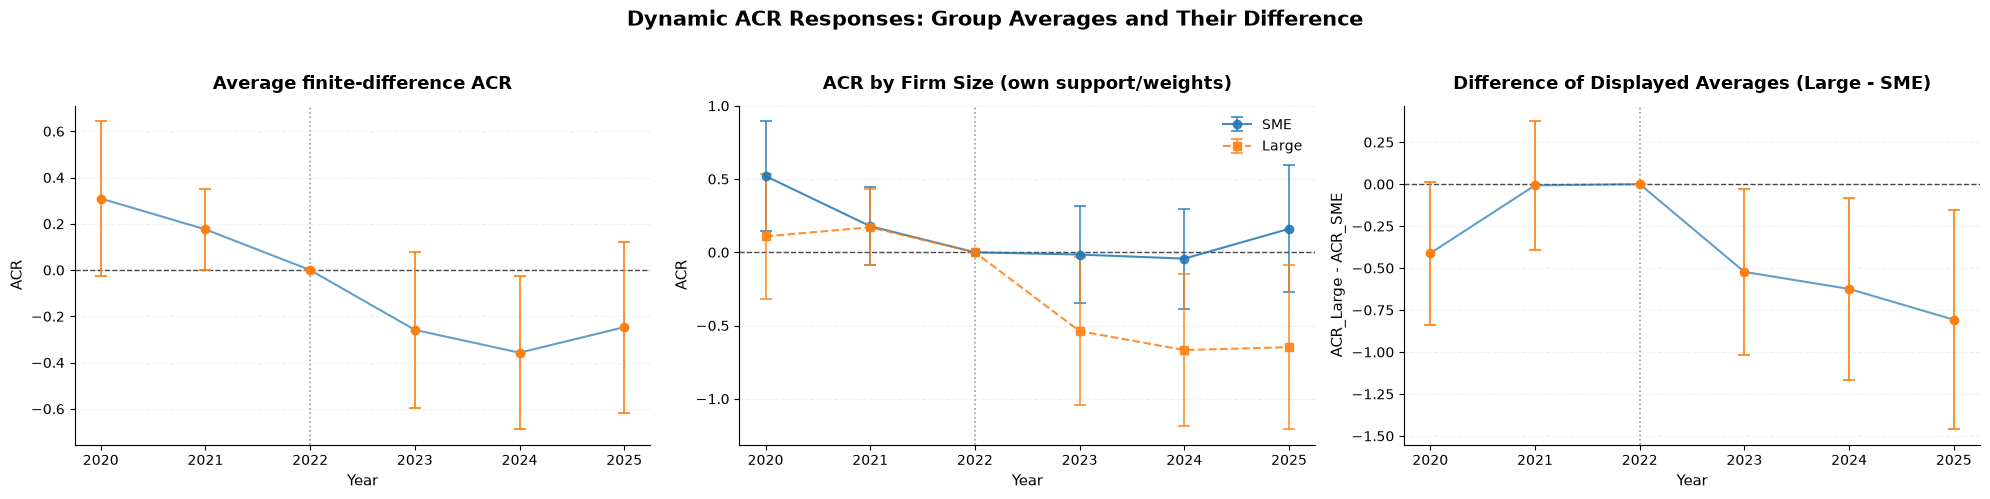

,year,total_n_used_firms,total_coverage,atet_o,atet_se,atet_lower,atet_upper,common_moderation_o,common_moderation_se,common_moderation_lower,...,acr_lower,acr_upper,sme_acr_o,sme_acr_se,sme_acr_lower,sme_acr_upper,large_acr_o,large_acr_se,large_acr_lower,large_acr_upper
0,2020,1405,0.704614,0.309373,0.170772,-0.025340,0.644087,-0.391002,0.215944,-0.814252,...,-0.025340,0.644087,0.520504,0.191459,0.145244,0.895764,0.108833,0.218467,-0.319363,0.537028
1,2021,1405,0.704614,0.175904,0.089618,0.000253,0.351554,-0.004593,0.193209,-0.383282,...,0.000253,0.351554,0.178184,0.136628,-0.089607,0.445976,0.170762,0.133040,-0.089995,0.431520
2,2022,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,2023,1405,0.704614,-0.258541,0.171479,-0.594639,0.077557,-0.506121,0.237152,-0.970939,...,-0.594639,0.077557,-0.015430,0.168522,-0.345734,0.314873,-0.538388,0.257154,-1.042408,-0.034367
4,2024,1405,0.704614,-0.357172,0.168663,-0.687751,-0.026593,-0.605914,0.265890,-1.127058,...,-0.687751,-0.026593,-0.043332,0.173999,-0.384370,0.297706,-0.667386,0.264037,-1.184899,-0.149873
5,2025,1405,0.704614,-0.246965,0.188728,-0.616872,0.122941,-0.787339,0.316076,-1.406848,...,-0.616872,0.122941,0.160133,0.220717,-0.272472,0.592738,-0.647599,0.285610,-1.207394,-0.087803


In [9]:
event_df = action_everything(
    var_name='office_ratio', group_col='ind_code', base_year=2022,
    n_splits=4, n_repeats=50, n_bootstrap=5000,
    diff_step=1e-5, ess=5, min_ess_prime=5,
    bootstrap_unit='industry', ind_counts=4,
    gap_policy='strict', size_difference='means',
    options={'memory_mode':'event_only', 'grid_chunk_points':4096,
             'search_n_jobs':2, 'crossfit_n_jobs':2},
)
event_df


In [ ]:
event_df = action_everything(
    var_name='office_ratio', group_col='ind_code', base_year=2022,
    n_splits=4, n_repeats=50, n_bootstrap=5000,
    diff_step=1e-5, ess=5, min_ess_prime=0,
    bootstrap_unit='industry', ind_counts=4,
    gap_policy='strict', size_difference='means',
    options={'memory_mode':'event_only', 'grid_chunk_points':4096,
             'search_n_jobs':2, 'crossfit_n_jobs':2},
)
event_df


부트스트랩 단위: industry (ind_code)
표본 범위: -2.2340 ≤ office_ratio ≤ 10, 기업 수: 2028
GPS(spline): 산업 151, OOF MSE=0.3125, 정규밀도 NLL=2.2091
